# **Практическая работа №6. Сравнительный анализ контролируемой классификации и неконтролируемой кластеризации спутниковых снимков в Google Earth Engine: выявление ошибок пропуска и скрытых пространственных структур**

## **1. Цель работы**

Обучить в Google Earth Engine классификаторы земного покрова по разметке Dynamic World и честно оценить их точность, найти кластеризацией на снимке территории объекты, которых нет в легенде готовых карт, и экспериментально определить, когда кластеризация цветов действительно уменьшает размер изображений.

## **2. Задачи работы**

1.  **Подготовить** летний композит Sentinel-2 и карту Dynamic World для территории своего варианта, рассмотреть снимок в естественных цветах и в инфракрасной комбинации каналов и записать гипотезы о том, что на нём можно найти;
2.  **Обучить** несколько классификаторов GEE на стратифицированной выборке с метками Dynamic World, сравнить случайную и пространственную проверку точности, оценить точность по классам и важность признаков;
3.  **Построить** карту классификации территории и сравнить её с картой Dynamic World;
4.  **Кластеризовать** снимок алгоритмом K-средних на серверах GEE при нескольких значениях $K$, дать кластерам названия, найти малые и необычные группы пикселей и проверить гипотезы;
5.  **Провести** эксперименты по сжатию фотографий, карты и снимка кластеризацией цветов: размер файлов, время, качество, сравнение со встроенным методом квантизации;
6.  **Сформулировать** выводы с конкретными числами.

> **Примечание.** Работа опирается на две лекции:
> - [лекция «Экспорт растровых данных и применение методов машинного обучения в среде Google Earth Engine»](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2) — **Разделы 1–4** (композиты, экспорт, выборки, классификаторы);
> - лекция «Кластеризация спутниковых снимков в среде Google Earth Engine» — **Разделы 2–6** (K-средних, интерпретация кластеров, поиск необычного, сжатие изображений).
>
> Код из лекций можно использовать как образец, но задания этой работы отличаются от лекционных примеров: другая разметка, другая территория, другие проверки.

> 📝 **Как выполнять работу.** Выполняйте ячейки по порядку. В ячейки `# Ваш код` впишите свой код; если в ячейке уже есть заготовка, замените в ней `...`. Ответы на вопросы пишите в ячейки **Ответ:** — двойной щелчок по ячейке, текст ответа, затем Shift+Enter. В ответах приводите числа из своих результатов.

---

## **3. Выбор территории и подготовка данных в Google Earth Engine**

### **3.1. Настройка рабочей среды и аутентификация**

In [1]:
%%capture
# Зависимости установлены локально (geemap, geedim, rasterio, scikit-learn, scikit-image);
# при запуске в Google Colab раскомментируйте строку ниже
# !pip install -U geemap geedim rasterio scikit-learn scikit-image

In [1]:
# Импорт основных библиотек для работы
import os
import time

import ee                        # Google Earth Engine
import geemap                    # Интерактивные карты и экспорт растров из GEE
import numpy as np               # Работа с массивами
import pandas as pd              # Работа с таблицами
import rasterio                  # Чтение экспортированных GeoTIFF
import matplotlib.pyplot as plt  # Построение графиков
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image            # Сохранение изображений, в том числе палитровых PNG
from sklearn.cluster import KMeans
from skimage import data as skdata
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%config InlineBackend.figure_format = 'jpeg'  # рисунки со снимками компактнее в JPEG

Перед началом работы с geemap и Google Earth Engine необходимо:

- **Зарегистрировать аккаунт Google Earth Engine**: Перейдите на [https://code.earthengine.google.com/register](https://code.earthengine.google.com/register) для создания аккаунта GEE. После регистрации нужно настроить проект Google Cloud и активировать API Earth Engine, следуя инструкциям [здесь](https://docs.google.com/document/d/1ZGSmrNm6_baqd8CHt33kIBWOlvkh-HLr46bODgJN1h0/edit?usp=sharing). GEE бесплатен для [некоммерческого и исследовательского использования](https://earthengine.google.com/noncommercial).

- **Проверить аутентификацию API**: Чтобы убедиться в правильности настройки аккаунта Earth Engine, запустите [этот тестовый блокнот](https://colab.research.google.com/github/gee-community/geemap/blob/master/docs/notebooks/geemap_colab.ipynb) в Google Colab.

In [2]:
import logging
import warnings

# geemap/geedim выводят предупреждения об устаревших API и о переполнении пула соединений
# при загрузке плиток — на результат они не влияют, поэтому скрываем их
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*STAC.*')
logging.getLogger('urllib3.connectionpool').setLevel(logging.ERROR)

# Аутентификация: при первом запуске открывается браузер для входа в Google-аккаунт,
# токен сохраняется в ~/.config/earthengine/credentials, и при повторных запусках вход не нужен
ee.Authenticate()

# Инициализация с проектом Google Cloud, в котором включён Earth Engine API
PROJECT_ID = 'test-507512'
ee.Initialize(project=PROJECT_ID)
print('Earth Engine инициализирован, проект:', PROJECT_ID)

Earth Engine инициализирован, проект: test-507512


### **3.2. Выбор территории**

Ниже перечислены территории, на которых есть объекты, плохо заметные на снимке в естественных цветах или отсутствующие в легенде готовых карт земного покрова: месторождения полезных ископаемых, нефтепромыслы, лесные гари, солепромыслы. Что именно и где искать, в таблице не сказано — это и предстоит выяснить. Номер варианта назначает преподаватель (если не назначен — номер в списке группы по модулю 7, нулю соответствует вариант 7).

#### **Таблица 1. Варианты территорий**

| **Вариант** | **Территория** | **Широта, долгота центра** | **Природная зона** |
|---|---|---|---|
| 1 | Олимпиадинское золоторудное месторождение, Красноярский край | 59.585, 92.990 | Южная тайга |
| 2 | Норильск: медно-никелевые и платиноидные руды, Красноярский край | 69.350, 88.200 | Лесотундра |
| 3 | Губкин, железные руды Курской магнитной аномалии, Белгородская область | 51.290, 37.700 | Лесостепь |
| 4 | Железногорск, железные руды Курской магнитной аномалии, Курская область | 52.360, 35.400 | Лесостепь |
| 5 | Самотлорское нефтяное месторождение, Ханты-Мансийский АО | 61.130, 76.750 | Средняя тайга, болота |
| 6 | Тайга в Забайкальском крае, район весенних лесных пожаров 2024 года | 54.665, 118.893 | Горная тайга |
| 7 | Озеро Баскунчак, Астраханская область | 48.200, 46.880 | Полупустыня |

Область интереса — квадрат 14×14 км вокруг центра. Все варианты анализируются по снимкам лета 2024 года.

In [3]:
PLACES = {
    1: ('Олимпиадинское золоторудное месторождение', 59.585, 92.990),
    2: ('Норильск', 69.350, 88.200),
    3: ('Губкин, Лебединский ГОК', 51.290, 37.700),
    4: ('Железногорск, Михайловский ГОК', 52.360, 35.400),
    5: ('Самотлорское нефтяное месторождение', 61.130, 76.750),
    6: ('Тайга в Забайкальском крае', 54.665, 118.893),
    7: ('Озеро Баскунчак', 48.200, 46.880),
}
YEAR = 2024

In [4]:
VARIANT = 2   # номер вашего варианта
PLACE, LAT, LON = PLACES[VARIANT]

# Область интереса — квадрат 14×14 км: круг радиусом 7 км вокруг центра и описанный около него прямоугольник
roi = ee.Geometry.Point([LON, LAT]).buffer(7000).bounds()
print(f'Вариант {VARIANT}: {PLACE}, центр {LAT}° с. ш., {LON}° в. д.')
print(f'Площадь области интереса: {roi.area(maxError=1).getInfo() / 1e6:.1f} км²')

Map = geemap.Map()
Map.add_basemap('Esri.WorldImagery')
Map.centerObject(roi, 12)
Map.addLayer(ee.Image().paint(roi, 0, 3), {'palette': ['yellow']}, 'Область интереса')
Map

Вариант 2: Норильск, центр 69.35° с. ш., 88.2° в. д.
Площадь области интереса: 194.9 км²


Map(center=[69.34998106248189, 88.20033996158713], controls=(WidgetControl(options=['position', 'transparent_b…

**Задание 3.2.** Рассмотрите территорию на карте-подложке. Ответьте до начала анализа.

**Вопрос:** Какие типы земного покрова вы видите на подложке? Какие объекты, связанные с названием территории (добыча, промыслы, пожары), вы ожидаете найти и где? Какие из них, по-вашему, не имеют своего класса в легенде Dynamic World (вода, деревья, трава, затопляемая растительность, сельхозкультуры, кустарники, застройка, голая земля, снег и лёд)?

**Ответ:** Территория — квадрат 14×14 км (195 км²) с центром в Норильске, на подложке хорошо различаются:

- **город** в центре: прямоугольная сетка кварталов многоэтажной застройки с красными и цветными крышами, внутри города — вытянутое озеро Долгое;
- **промышленные площадки** к западу и югу от города: корпуса заводов и обогатительной фабрики, железные и автодороги, трубопроводы, пустыри;
- **хвостохранилище** на северо-западе: многоугольник примерно 3×4 км, обвалованный дамбами, с серыми «пляжами» и серо-бирюзовой водой; к юго-западу от города — ещё несколько прудов-отстойников с бирюзовой водой;
- **отвалы и карьер** на юге: бурые ступенчатые насыпи с плоским верхом размером 2–3 км, террасированная выработка с маленькими озёрами на дне, чёрное пятно к юго-востоку от города;
- **голые горные склоны** на юге и юго-востоке с белыми пятнами снежников (на снимке лета!);
- **лесотундра** на северо-востоке: редколесья лиственницы, кустарники, болота и сотни мелких термокарстовых озёр; в северо-восточном углу — крупная река с причалами.

Вокруг промзоны на несколько километров почти нет зелени — это техногенная пустошь на месте погибшей от выбросов диоксида серы растительности.

**Что ожидаю найти.** Добыча и переработка медно-никелевых и платиноидных руд оставляет: карьер и отвалы пустой породы (юг, склоны гор), хвосты обогащения (хвостохранилище на северо-западе и отстойники к юго-западу от города), шлак металлургических заводов (тёмные отвалы у промплощадок), техногенную пустошь вокруг заводов.

**Чего нет в легенде Dynamic World.** Своего класса нет ни у одного из этих объектов: хвосты, шлак, отвалы и карьер DW может отнести только к «голой земле», «застройке» или «воде», а погибшую и угнетённую растительность — к «голой земле», «кустарникам» или «траве». Снежники класс имеют («снег и лёд»).

### **3.3. Летний композит Sentinel-2 и спектральные индексы**

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **разделы 2.2–2.3** (фильтрация, маска облаков по каналу SCL, медианный композит) и **3.3** (индексы).

**Задание 3.3.** Постройте медианный композит `composite` снимков Sentinel-2 уровня 2A (`COPERNICUS/S2_SR_HARMONIZED`) за 1 июня – 31 августа 2024 года:
- каналы `BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']`, значения отражения переведены в диапазон 0–1 (деление на 10000);
- снимки с облачностью `CLOUDY_PIXEL_PERCENTAGE` < 20%, облака и тени замаскированы по каналу SCL (классы 3, 8, 9, 10);
- к композиту добавлены индексы `NDVI` (B8, B4), `NDWI` (B3, B8) и `NDBI` (B11, B8);
- список всех признаков сохраните в переменную `FEATURES` — он понадобится для обучения классификаторов.

In [5]:
BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
START, END = f'{YEAR}-06-01', f'{YEAR}-09-01'   # 1 июня – 31 августа (конечная дата не включается)


def mask_clouds(image):
    """Маска облаков и теней по каналу SCL и перевод отражения в диапазон 0–1."""
    scl = image.select('SCL')
    # 3 — тени облаков, 8 и 9 — облака средней и высокой вероятности, 10 — перистые облака
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.select(BANDS).updateMask(mask).divide(10000).copyProperties(image, ['system:time_start'])


collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
              .filterBounds(roi)
              .filterDate(START, END)
              .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
              .map(mask_clouds))
composite = collection.median().clip(roi)

# Спектральные индексы
composite = composite.addBands([
    composite.normalizedDifference(['B8', 'B4']).rename('NDVI'),    # растительность
    composite.normalizedDifference(['B3', 'B8']).rename('NDWI'),    # вода
    composite.normalizedDifference(['B11', 'B8']).rename('NDBI'),   # застройка и открытый грунт
])
FEATURES = composite.bandNames().getInfo()

dates = collection.aggregate_array('system:time_start').map(lambda t: ee.Date(t).format('dd.MM')).getInfo()
print(f'Снимков Sentinel-2 в композите: {len(dates)}, дат съёмки: {len(set(dates))}')
print('Даты съёмки:', ', '.join(sorted(set(dates), key=lambda d: (d[3:], d[:2]))))
print('Признаки (FEATURES):', FEATURES)

Снимков Sentinel-2 в композите: 27, дат съёмки: 19
Даты съёмки: 17.06, 26.06, 09.07, 16.07, 17.07, 19.07, 21.07, 22.07, 29.07, 31.07, 01.08, 03.08, 05.08, 06.08, 08.08, 10.08, 11.08, 15.08, 23.08
Признаки (FEATURES): ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI']


### **3.4. Карта Dynamic World**

Dynamic World — карта земного покрова с пикселем 10 м, которую Google строит нейросетью для каждого снимка Sentinel-2. В этой работе она служит **разметкой для обучения**: классификатор будет учиться повторять её классы по спектру пикселей.

**Задание 3.4.** Получите `dynamic_world` — моду канала `label` коллекции `GOOGLE/DYNAMICWORLD/V1` за тот же период (наиболее частый класс в каждом пикселе), обрежьте по `roi` и переименуйте канал в `'class'`.

In [6]:
DW_NAMES = ['Вода', 'Деревья', 'Трава', 'Затопл. растительность', 'Культуры',
            'Кустарники', 'Застройка', 'Голая земля', 'Снег и лед']
DW_COLORS = ['#419bdf', '#397d49', '#88b053', '#7a87c6', '#e49635',
             '#dfc35a', '#c4281b', '#a59b8f', '#b39fe1']

In [7]:
dw_collection = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
                 .filterBounds(roi)
                 .filterDate(START, END)
                 .select('label'))
# Наиболее частый класс пикселя за лето (медиана номеров классов смысла не имеет)
dynamic_world = dw_collection.mode().clip(roi).rename('class')
print(f'Карт Dynamic World за лето {YEAR}: {dw_collection.size().getInfo()}')

Карт Dynamic World за лето 2024: 48


### **3.5. Экспорт и просмотр растров**

Для анализа на локальной машине нужны шесть основных каналов композита, индексы NDVI и NDWI и карта Dynamic World. Растры экспортируются в проекции UTM с пикселем 10 м и загружаются плитками 256×256 пикселей. Карты классов сохраняются с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпало бы с классом «Вода». **Если экспорт идёт слишком долго, увеличьте `SCALE` до 20 м.**

In [8]:
#@title Готовая функция экспорта
SCALE = 10  # размер пикселя, м

def utm_crs(region):
    """Код EPSG зоны UTM для центра области."""
    lon, lat = region.centroid(maxError=1).coordinates().getInfo()
    return f'EPSG:{(32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1}'

def export_georeferenced_raster(image, region, filename, scale=SCALE, dtype='float32', tile_size=256):
    """Экспорт в GeoTIFF в проекции UTM с загрузкой плитками."""
    geemap.download_ee_image(image=image, filename=filename, region=region, scale=scale,
                             crs=utm_crs(region), dtype=dtype, max_tile_dim=tile_size)
    return filename

def read_raster(filename):
    """Массив каналов растра (каналы, строки, столбцы)."""
    with rasterio.open(filename) as src:
        return src.read()

os.makedirs('data', exist_ok=True)

**Задание 3.5.** Экспортируйте каналы `LOCAL_BANDS` композита в `data/sentinel2.tif` (тип `float32`) и `dynamic_world` в `data/dynamic_world.tif` (тип `int16`). Загрузите их в массивы `bands` и `dw`, получите маску пикселей с данными `valid` (все каналы конечны и `dw >= 0`), размеры `H`, `W` и площадь пикселя в гектарах `PIXEL_AREA_HA`.

In [9]:
LOCAL_BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI']

In [10]:
export_georeferenced_raster(composite.select(LOCAL_BANDS), roi, 'data/sentinel2.tif')
export_georeferenced_raster(dynamic_world, roi, 'data/dynamic_world.tif', dtype='int16')

with rasterio.open('data/sentinel2.tif') as src:
    print(f'Sentinel-2: {src.crs}, пиксель {src.res[0]:g}×{src.res[1]:g} м, каналы {src.descriptions}, '
          f'тип {src.dtypes[0]}, NoData {src.nodata}')
    PIXEL_AREA_HA = abs(src.res[0] * src.res[1]) / 10000
with rasterio.open('data/dynamic_world.tif') as src:
    print(f'Dynamic World: тип {src.dtypes[0]}, NoData {src.nodata}')

bands = read_raster('data/sentinel2.tif').astype('float32')   # (8 каналов, строки, столбцы)
dw = read_raster('data/dynamic_world.tif')[0]                    # номера классов 0–8, NoData < 0

valid = np.isfinite(bands).all(axis=0) & (dw >= 0)   # пиксели с данными
H, W = valid.shape
print(f'Размер растра: {W}×{H} пикселей, площадь пикселя {PIXEL_AREA_HA:g} га, '
      f'пикселей с данными: {valid.sum():,} из {H * W:,} ({valid.sum() * PIXEL_AREA_HA:,.0f} га)')

  0%|          |0/288 tiles [00:00<?]

  0%|          |0/36 tiles [00:00<?]

Sentinel-2: EPSG:32645, пиксель 10×10 м, каналы ('B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI'), тип float32, NoData -inf
Dynamic World: тип int16, NoData -32768.0
Размер растра: 1426×1433 пикселей, площадь пикселя 0.01 га, пикселей с данными: 1,964,540 из 2,043,458 (19,645 га)


Человеческий глаз видит только видимый диапазон, поэтому многие объекты на снимке в естественных цветах неразличимы. Комбинация **B12 – B8 – B4** (коротковолновый ИК, ближний ИК, красный) отображает здоровую растительность ярко-зелёной (высокое отражение в B8), открытый грунт, горные породы и гари — красно-бурыми и сиреневыми (высокое отражение в B12), воду — почти чёрной. Покажем снимок в обеих комбинациях и карту Dynamic World.

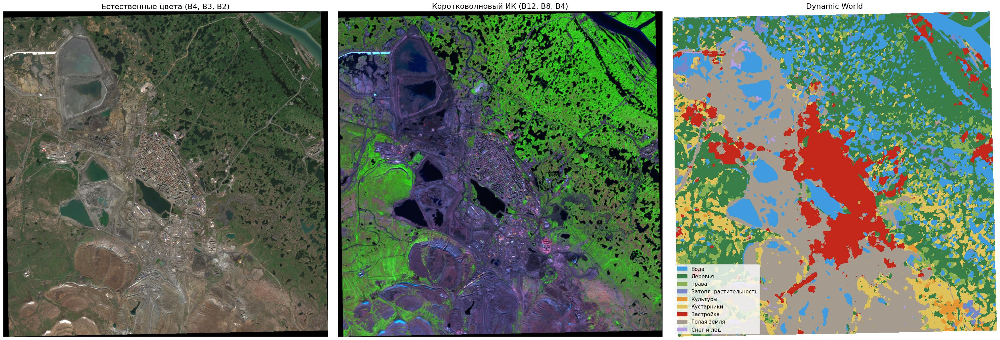

Деревья                   5628.8
Голая земля               5058.2
Вода                      3143.6
Застройка                 2146.5
Кустарники                2021.6
Трава                     1140.7
Затопл. растительность     264.8
Культуры                   164.5
Снег и лед                  76.5
Name: Площадь, га, dtype: float64

In [11]:
#@title Готовая функция: снимок в естественных цветах и в комбинации B12-B8-B4
def stretch(x, high):
    """Линейное растяжение значений отражения в диапазон 0-1."""
    return np.clip(np.nan_to_num(x, nan=0, posinf=0, neginf=0) / high, 0, 1)

rgb = stretch(np.dstack([bands[2], bands[1], bands[0]]), 0.3) ** (1 / 1.4)   # B4, B3, B2
swir = np.dstack([stretch(bands[5], 0.4), stretch(bands[3], 0.45), stretch(bands[2], 0.25)])   # B12, B8, B4
dw_cmap = ListedColormap(DW_COLORS)
dw_legend = [Patch(color=col, label=name) for col, name in zip(DW_COLORS, DW_NAMES)]

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
axes[0].imshow(rgb)
axes[0].set_title('Естественные цвета (B4, B3, B2)', fontsize=16)
axes[1].imshow(swir)
axes[1].set_title('Коротковолновый ИК (B12, B8, B4)', fontsize=16)
axes[2].imshow(np.ma.masked_less(dw, 0), cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[2].set_title('Dynamic World', fontsize=16)
axes[2].legend(handles=dw_legend, loc='lower left', fontsize=11)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

dw_areas = pd.Series(np.bincount(dw[valid], minlength=9) * PIXEL_AREA_HA, index=DW_NAMES, name='Площадь, га')
dw_areas[dw_areas > 0].sort_values(ascending=False).round(1)

**Задание 3.5 (продолжение).** Сравните три изображения. Запишите гипотезы: какие участки выглядят необычно на комбинации B12–B8–B4, хотя на снимке в естественных цветах не выделяются (или наоборот), и к какому классу Dynamic World их отнёс. Гипотезы проверите в разделе 5.

#### **Таблица 2. Гипотезы до анализа**

| № | Наблюдение (где, как выглядит в естественных цветах и в B12–B8–B4) | Класс Dynamic World | Гипотеза: что это за объект | Как проверить |
|---|---|---|---|---|
| 1 | Северо-запад: многоугольник ~3×4 км в дамбах. В естественных цветах — серые «пляжи» и серо-бирюзовая вода, в B12–B8–B4 — сиреневые пляжи без зелени и тёмно-синяя вода | Голая земля, Вода | Хвостохранилище обогатительной фабрики: намытые хвосты (тонко измельчённая порода) и осветлённая вода | Отдельный кластер тёмных пикселей с плоским профилем и NDVI ≈ 0; по DW он должен делиться между «голой землёй» и «водой» |
| 2 | Западнее хвостохранилища: прямая белая полоса ~2,3 км × ~80 м, разделённая перемычками. В естественных цветах белая, как снег, в B12–B8–B4 светло-голубая — почти как снежники на юге | Застройка, Голая земля, местами Снег и лёд | Снег или наледь в техническом канале, не растаявшие за лето | У снега и льда отражение в B11–B12 очень низкое; сравнить спектральный профиль полосы с профилем снежников |
| 3 | Юг: бурые ступенчатые насыпи с плоским верхом (2–3 км) и террасированная выработка; к ЮВ от города — чёрное пятно ~1 км. В B12–B8–B4 насыпи фиолетово-сиреневые (растительности нет, высокое отражение в SWIR), чёрное пятно тёмное во всех каналах | Голая земля, местами Кустарники и Застройка | Отвалы пустой породы и карьер рудника; чёрное пятно — шлакоотвал металлургического завода | Кластеры с NDVI ≈ 0 и плоским «минеральным» профилем; шлак, если гипотеза верна, попадёт в один кластер с тёмными хвостами |
| 4 | Юго-восточный угол: бурые склоны. В B12–B8–B4 красновато-сиреневые с пятнами зелени, тогда как лесотундра на северо-востоке ярко-зелёная | Кустарники, Деревья, местами **Культуры** | Сельского хозяйства на 69° с. ш. нет: это сухая горная кустарничковая тундра и угнетённая растительность; «Культуры» — ошибка DW | Кластер с умеренным NDVI и повышенным B11; сравнить его состав с DW |

<details>
<summary><b>Пример формулировки</b></summary>

*Условный пример:* «В центре — светлое пятно неправильной формы около 2×3 км, в естественных цветах серо-бежевое, в B12–B8–B4 сиреневое, вокруг ярко-зелёная тайга. Dynamic World относит его к кустарникам и голой земле. Гипотеза: карьер и отвалы пустой породы. Проверка: отдельный кластер со спектром без растительности и высоким отражением в B11–B12».

</details>

**Ответ:** Гипотезы записаны в таблицу 2. Главное, что видно ещё до анализа: на комбинации B12–B8–B4 техногенные объекты (хвосты, отвалы, промзона) выглядят одинаково сиреневыми и резко отделяются от ярко-зелёной лесотундры. На снимке в естественных цветах и отвалы, и тундра бурые, и граница между ними видна намного хуже.

Dynamic World сводит все эти объекты к «голой земле» (5 058 га, 26 % территории). Белая полоса у хвостохранилища в естественных цветах выглядит как снег. А 164,5 га «культур» на юго-востоке за полярным кругом — явная ошибка DW.

---

## **4. Классификация с учителем по разметке Dynamic World**

В лекции классификаторы обучались по карте ESA WorldCover. Здесь разметкой будет Dynamic World: классификатор учится по спектру пикселя предсказывать класс, который поставил бы Dynamic World. Это удобно — разметку не нужно создавать вручную, — но у такого подхода есть пределы: модель повторит и классы, и ошибки разметки. Их мы и увидим.

### **4.1. Стратифицированная обучающая выборка**

Классы на территории занимают очень разную площадь: например, тайга — десятки квадратных километров, застройка — несколько гектаров. Простая случайная выборка (`sample`) почти не содержит точек редких классов, и модель их не выучит. **Стратифицированная выборка** (`stratifiedSample`) берёт заданное число точек из каждого класса: если пикселей класса меньше, берутся все.

**Параметры метода `stratifiedSample`:**
- `numPoints` — число точек на класс
- `classBand` — канал с метками классов
- `region`, `scale` — область и размер пикселя выборки
- `seed` — начальное значение генератора для воспроизводимости
- `tileScale` — дробление вычислений на более мелкие плитки (помогает избежать ошибки нехватки памяти)

К каждой точке сразу добавим номер блока «шахматной доски» со стороной 1 км — он понадобится для пространственной проверки в разделе 4.2.

In [12]:
# Номер блока шахматной доски 1×1 км: 0 — «чёрные» клетки, 1 — «белые»
BLOCK_SIZE = 1000
blocks = (ee.Image.pixelCoordinates(ee.Projection(utm_crs(roi)))
          .divide(BLOCK_SIZE).floor().reduce('sum').mod(2).toInt().rename('block'))

**Задание 4.1.** Получите выборку `samples`: по 400 точек каждого класса из изображения `composite.addBands(dynamic_world).addBands(blocks)` (`scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Проекция UTM обязательна: по умолчанию выборка берётся в географических координатах, где пиксель «10 м» по долготе в высоких широтах вдвое уже, и точки редких классов дублируются. Выведите число точек по классам (`aggregate_histogram('class')`) с названиями классов. Классы, у которых меньше 100 точек, исключите из выборки (`ee.Filter.inList`): по нескольким десяткам точек нельзя ни обучить, ни проверить модель. Список оставшихся кодов классов сохраните в `CLASSES`.

In [13]:
samples_all = (composite.addBands(dynamic_world).addBands(blocks)
               .stratifiedSample(numPoints=400, classBand='class', region=roi, scale=SCALE,
                                 projection=utm_crs(roi), seed=42, tileScale=4))

# Число точек по классам
histogram = samples_all.aggregate_histogram('class').getInfo()
sample_counts = pd.Series({int(float(k)): int(v) for k, v in histogram.items()}).sort_index()
sample_table = pd.DataFrame({'Класс': [DW_NAMES[k] for k in sample_counts.index],
                             'Точек': sample_counts.values,
                             'Площадь по DW, га': [dw_areas[DW_NAMES[k]] for k in sample_counts.index]},
                            index=pd.Index(sample_counts.index, name='Код'))
display(sample_table)

# Классы, у которых меньше 100 точек, исключаем: по нескольким десяткам точек модель не обучить и не проверить
CLASSES = [k for k, n in sample_counts.items() if n >= 100]
samples = samples_all.filter(ee.Filter.inList('class', CLASSES))
excluded = [DW_NAMES[k] for k in sample_counts.index if k not in CLASSES]
print(f'Классы выборки (CLASSES): {CLASSES}')
print(f'Исключены: {", ".join(excluded) if excluded else "нет"}')
print(f'Точек в выборке: {samples.size().getInfo()}')

,Класс,Точек,"Площадь по DW, га"
Код,,,
0,Вода,400,3143.59
1,Деревья,400,5628.82
2,Трава,400,1140.74
3,Затопл. растительность,400,264.82
4,Культуры,400,164.50
5,Кустарники,400,2021.64
6,Застройка,400,2146.52
7,Голая земля,400,5058.23
8,Снег и лед,400,76.54


Классы выборки (CLASSES): [0, 1, 2, 3, 4, 5, 6, 7, 8]
Исключены: нет
Точек в выборке: 3600


### **4.2. Случайная и пространственная проверка точности**

В лекции выборка делилась на обучающую и проверочную случайно (70/30). Но соседние пиксели снимка почти одинаковы: если один пиксель поля попал в обучение, а соседний — в проверку, модель «узнаёт» знакомое место, а не применяет выученное правило. Точность на такой проверке завышена. Честнее проверять модель на **других участках** территории: обучать на «чёрных» клетках шахматной доски, а проверять на «белых». Так оценивают, как модель поведёт себя на новом месте.

**Задание 4.2.** Создайте два разбиения выборки:
- случайное: `randomColumn('random', 42)`, обучение — `random < 0.7`, проверка — остальные;
- пространственное: обучение — `block == 0`, проверка — `block == 1`.

Для каждого разбиения обучите `ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42)` на признаках `FEATURES` и рассчитайте общую точность и каппу на проверочной части. Сохраните разбиения в словарь `splits = {'Случайная': (train, test), 'Пространственная': (train, test)}` и выведите таблицу результатов.

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **раздел 4.2** (разделение по `randomColumn`) и **4.3** (`train`, `classify`, `errorMatrix`).

In [14]:
def train_and_test(classifier, train, test):
    """Обучает классификатор на train и возвращает модель и матрицу ошибок на test."""
    model = classifier.train(features=train, classProperty='class', inputProperties=FEATURES)
    matrix = test.classify(model).errorMatrix('class', 'classification')
    return model, matrix


samples_random = samples.randomColumn('random', 42)
splits = {
    'Случайная': (samples_random.filter(ee.Filter.lt('random', 0.7)),
                  samples_random.filter(ee.Filter.gte('random', 0.7))),
    'Пространственная': (samples.filter(ee.Filter.eq('block', 0)),     # «чёрные» клетки 1×1 км
                         samples.filter(ee.Filter.eq('block', 1))),    # «белые» клетки 1×1 км
}

rows = []
for split_name, (train, test) in splits.items():
    _, matrix = train_and_test(ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42), train, test)
    info = ee.Dictionary({'train': train.size(), 'test': test.size(),
                          'accuracy': matrix.accuracy(), 'kappa': matrix.kappa()}).getInfo()
    rows.append({'Проверка': split_name, 'Обучающих точек': info['train'], 'Проверочных точек': info['test'],
                 'Общая точность': info['accuracy'], 'Каппа': info['kappa']})

split_metrics = pd.DataFrame(rows).set_index('Проверка')
diff = split_metrics.loc['Случайная', ['Общая точность', 'Каппа']] - split_metrics.loc['Пространственная', ['Общая точность', 'Каппа']]
print(f'Random Forest: случайная проверка завышает общую точность на {diff["Общая точность"]:.3f}, каппу — на {diff["Каппа"]:.3f}')
split_metrics.round(3)

Random Forest: случайная проверка завышает общую точность на 0.019, каппу — на 0.022


,Обучающих точек,Проверочных точек,Общая точность,Каппа
Проверка,,,,
Случайная,2547,1053,0.567,0.513
Пространственная,1769,1831,0.548,0.491


**Вопрос:** На сколько различаются точность и каппа случайного леса при случайной и пространственной проверке? Почему? Какой оценке вы бы доверяли, если модель нужно применить к соседнему участку тайги или к другому месторождению?

**Ответ:** Для случайного леса случайная проверка дала общую точность **0,567** и каппу **0,513**, пространственная — **0,548** и **0,491**. Случайная проверка завышает точность на 0,019, а каппу на 0,022, то есть примерно на 2 процентных пункта.

**Почему результаты различаются.** Соседние пиксели почти одинаковы. При случайном разбиении проверочная точка может лежать рядом с обучающей точкой на том же объекте, и модель «узнаёт» место. При шахматном разбиении она проверяется на других километровых клетках.

**Почему разница небольшая.** Выборка разреженная: 3 600 точек на 19 645 га, то есть одна точка на 5,5 га, или в среднем одна на ~230 м. Поэтому у большинства проверочных точек нет обучающих соседей в пределах нескольких пикселей. Сильнее «подглядывание» действует у редких классов. Например, у «снега и льда» 400 точек приходится на 76,5 га: выбран примерно каждый 19-й пиксель класса.

Низкая точность (~0,55) в целом объясняется не утечкой, а шумной разметкой DW и спектральной близостью классов растительности (раздел 4.4).

**Какой оценке доверять.** Для соседнего участка тайги или другого месторождения я бы доверял только пространственной оценке (0,548 / 0,491), и то как оценке сверху. Клетки одной территории сняты в один сезон, при одном освещении и в одном ландшафте. На другом месторождении (другая природная зона, другие породы и хвосты) точность будет ниже.

### **4.3. Сравнение классификаторов**

**Задание 4.3.** Выберите не менее трёх классификаторов из лекции (раздел 4.3) и сравните их **на пространственном разбиении**. Наивный байесовский классификатор не берите: он рассчитан на неотрицательные целые признаки (счётчики), а у нас дробные отражения и индексы. Сохраните обученные модели в словарь `models`, матрицы ошибок — в `matrices`, таблицу точности и каппы — в `metrics`, название лучшей модели по каппе — в `best_name`.

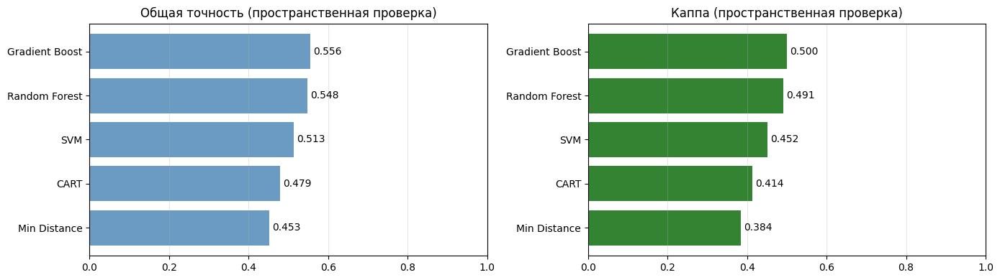

Лучшая модель по каппе: Gradient Boost


,Общая точность,Каппа
Gradient Boost,0.556,0.500
Random Forest,0.548,0.491
SVM,0.513,0.452
CART,0.479,0.414
Min Distance,0.453,0.384


In [15]:
classifiers = {
    'Random Forest': ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42),
    'Gradient Boost': ee.Classifier.smileGradientTreeBoost(numberOfTrees=50, shrinkage=0.1, seed=42),
    'CART': ee.Classifier.smileCart(),
    'SVM': ee.Classifier.libsvm(kernelType='RBF', gamma=0.1, cost=10),
    'Min Distance': ee.Classifier.minimumDistance(metric='euclidean'),
}

train, test = splits['Пространственная']
models, matrices = {}, {}
for name, clf in classifiers.items():
    models[name], matrices[name] = train_and_test(clf, train, test)

# Все метрики одним запросом к серверу
scores = ee.Dictionary({name: ee.List([m.accuracy(), m.kappa()]) for name, m in matrices.items()}).getInfo()
metrics = pd.DataFrame({name: {'Общая точность': acc, 'Каппа': kappa} for name, (acc, kappa) in scores.items()}).T
metrics = metrics.sort_values('Каппа', ascending=False)
best_name = metrics['Каппа'].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, column, color in zip(axes, metrics.columns, ['steelblue', 'darkgreen']):
    ordered = metrics[column].sort_values()
    bars = ax.barh(ordered.index, ordered.values, color=color, alpha=0.8)
    ax.bar_label(bars, fmt='%.3f', padding=3)
    ax.set_xlim(0, 1)
    ax.set_title(f'{column} (пространственная проверка)')
    ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Лучшая модель по каппе: {best_name}')
metrics.round(3)

### **4.4. Точность по классам**

Общая точность скрывает, какие классы модель путает. Для каждого класса считают две точности:

- **точность производителя** (`producersAccuracy`, она же полнота) — какая доля пикселей класса в разметке распознана моделью правильно; низкое значение означает, что модель **пропускает** класс;
- **точность пользователя** (`consumersAccuracy`, она же точность в смысле precision) — какая доля пикселей, отнесённых моделью к классу, действительно относится к нему; низкое значение означает, что модель **приписывает** классу чужие пиксели.

*Условный пример:* если из 100 пикселей «Застройки» модель нашла 60, точность производителя 0,6; если при этом она назвала «Застройкой» 80 пикселей и 60 из них верны, точность пользователя 0,75.

**Задание 4.4.** Для лучшей модели постройте таблицу `per_class`: название класса, точность производителя и точность пользователя для классов из `CLASSES`. Матрица ошибок GEE индексируется кодами классов, поэтому строка `producersAccuracy()` — это список длиной «максимальный код + 1». Постройте также тепловую карту матрицы ошибок, нормированной по строкам (истинным классам).

,Класс,Точек проверки,Точность производителя,Точность пользователя
Код,,,,
0,Вода,205,0.693,0.776
8,Снег и лед,199,0.673,0.950
7,Голая земля,195,0.636,0.510
4,Культуры,200,0.585,0.588
2,Трава,212,0.566,0.446
6,Застройка,198,0.535,0.549
1,Деревья,208,0.495,0.464
3,Затопл. растительность,203,0.429,0.558
5,Кустарники,211,0.403,0.378


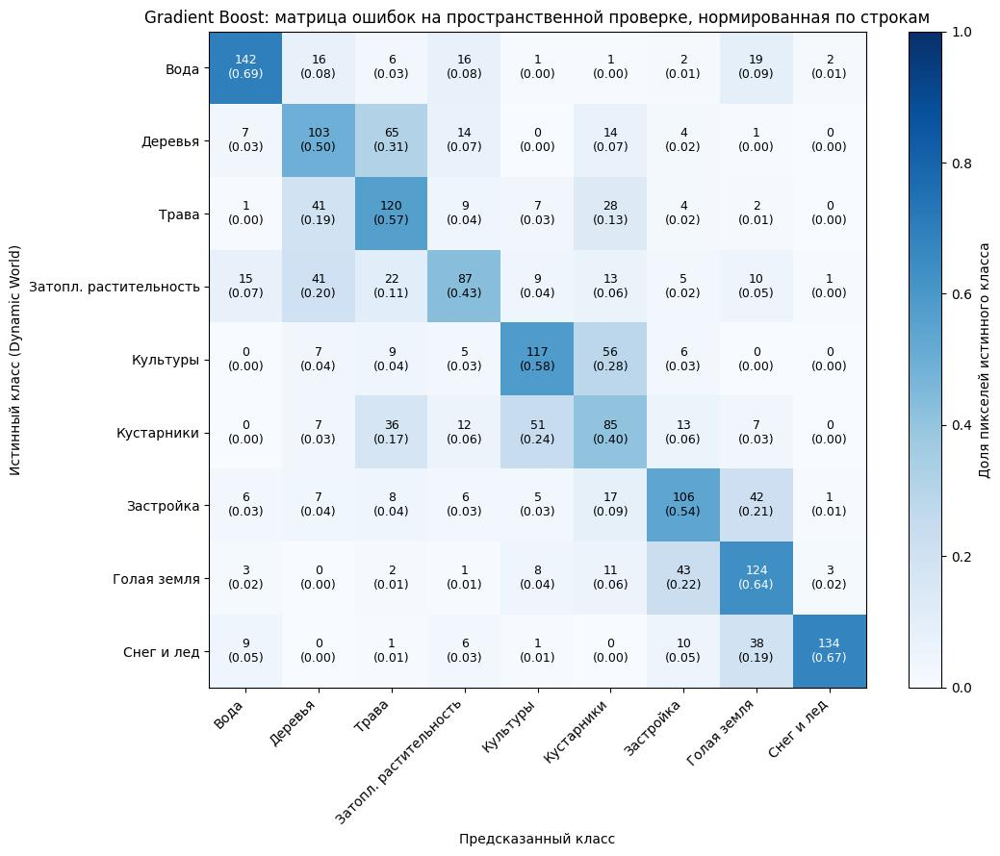

Главная ошибка пропуска каждого класса (куда уходят его пиксели):
  Вода                     → Голая земля (9%)
  Деревья                  → Трава (31%)
  Трава                    → Деревья (19%)
  Затопл. растительность   → Деревья (20%)
  Культуры                 → Кустарники (28%)
  Кустарники               → Культуры (24%)
  Застройка                → Голая земля (21%)
  Голая земля              → Застройка (22%)
  Снег и лед               → Голая земля (19%)


In [16]:
best_matrix = matrices[best_name]
info = ee.Dictionary({'matrix': best_matrix.array(),
                      'producers': best_matrix.producersAccuracy(),
                      'consumers': best_matrix.consumersAccuracy()}).getInfo()

# Матрица GEE индексируется кодами классов: строка i — истинный класс i, столбец j — предсказанный j
cm = np.array(info['matrix'])
producers = np.array(info['producers']).ravel()   # форма (макс. код + 1, 1)
consumers = np.array(info['consumers']).ravel()   # форма (1, макс. код + 1)

per_class = pd.DataFrame({
    'Класс': [DW_NAMES[c] for c in CLASSES],
    'Точек проверки': cm.sum(axis=1)[CLASSES],
    'Точность производителя': producers[CLASSES],
    'Точность пользователя': consumers[CLASSES],
}, index=pd.Index(CLASSES, name='Код'))
display(per_class.sort_values('Точность производителя', ascending=False).round(3))

# Матрица, нормированная по строкам (истинным классам)
cm_classes = cm[np.ix_(CLASSES, CLASSES)]
cm_norm = cm_classes / cm_classes.sum(axis=1, keepdims=True)
names = [DW_NAMES[c] for c in CLASSES]

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f'{cm_classes[i, j]}\n({cm_norm[i, j]:.2f})', ha='center', va='center', fontsize=9,
                color='white' if cm_norm[i, j] > 0.6 else 'black')
ax.set_xticks(range(len(CLASSES)), names, rotation=45, ha='right')
ax.set_yticks(range(len(CLASSES)), names)
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс (Dynamic World)')
ax.set_title(f'{best_name}: матрица ошибок на пространственной проверке, нормированная по строкам')
plt.colorbar(im, ax=ax, fraction=0.046, label='Доля пикселей истинного класса')
plt.tight_layout()
plt.show()

# С какими классами путается каждый класс сильнее всего
off_diagonal = cm_norm.copy()
np.fill_diagonal(off_diagonal, 0)
confusions = pd.DataFrame(off_diagonal, index=names, columns=names)
print('Главная ошибка пропуска каждого класса (куда уходят его пиксели):')
for name in names:
    print(f'  {name:24s} → {confusions.loc[name].idxmax()} ({confusions.loc[name].max():.0%})')

**Вопрос:** Какие классы модель распознаёт лучше всего и хуже всего? С какими классами путается самый проблемный класс? Объясните, почему спектрально эти классы похожи.

**Ответ:** Лучшая модель на пространственной проверке — Gradient Boost (каппа 0,500).

**Лучше всего** модель распознаёт:
- **воду**: точность производителя 0,693, пользователя 0,776;
- **снег и лёд**: 0,673 и 0,950;
- **голую землю**: 0,636 и 0,510.

**Хуже всего:**
- **кустарники**: 0,403 и 0,378;
- **затопляемую растительность**: 0,429 и 0,558;
- **деревья**: 0,495 и 0,464.

**Самый проблемный класс — «кустарники»:**
- 24 % его проверочных точек модель отнесла к «культурам», 17 % — к «траве», 6 % — к «затопл. растительности» и «застройке»;
- в обратную сторону 28 % «культур» ушли в «кустарники»;
- кроме того, «деревья» путаются с «травой» (31 %), «застройка» — с «голой землёй» (21 % и 22 % в обе стороны).

**Почему кустарники спектрально похожи на соседние классы.** В лесотундре 10-метровый пиксель — это смесь низких кустарников (ерник, ивы), трав, мхов, лишайников и редких лиственниц. У «кустарников», «травы», «деревьев» и «культур» здесь одинаковый тип спектра: низкое отражение в красном, высокое в ближнем ИК, NDVI 0,4–0,7. Классы различаются высотой и строением растительности, а оптический спектр одного летнего композита этого не передаёт. Dynamic World разделяет их с помощью пространственного контекста и сезонного хода, которых у нашей модели нет.

Отдельно о «культурах»: на 69° с. ш. полей нет. Значит, сама разметка DW относит к «культурам» участки кустарничковой тундры, и модель учится различать классы, которые в разметке разделены произвольно.

С «застройкой» и «голой землёй» похожая ситуация: бетон, асфальт, крыши, отвалы и техногенный грунт — минеральные поверхности с плоским спектром.

### **4.5. Важность признаков**

Случайный лес оценивает, насколько каждый признак помогает разделять классы. В GEE оценки возвращает метод `explain()` обученной модели (ключ `importance`).

**Задание 4.5.** Получите важность признаков модели `models['Random Forest']`, переведите её в доли от суммы и постройте горизонтальную столбчатую диаграмму, отсортированную по убыванию важности.

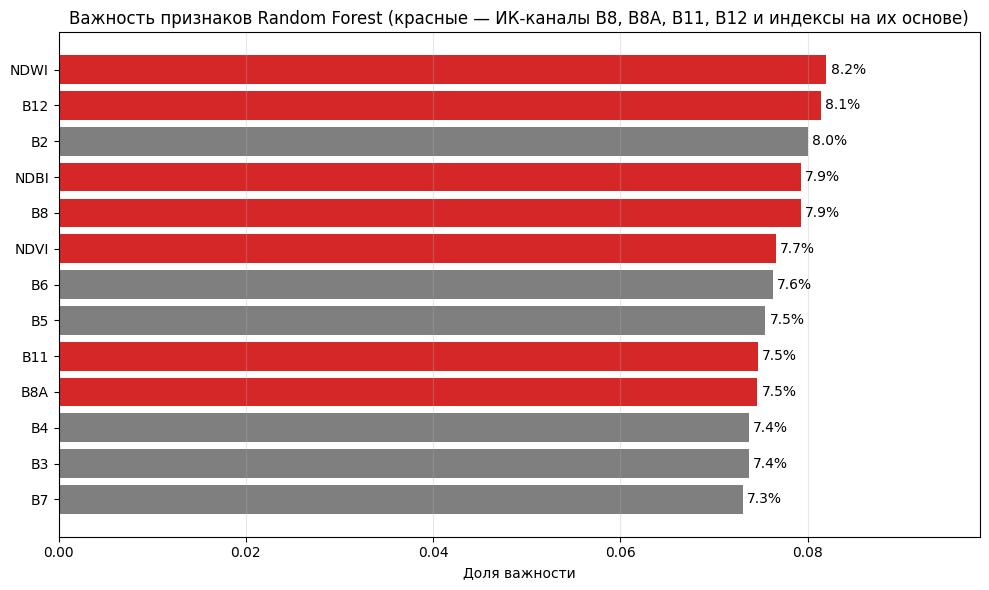

Доля важности ИК-каналов B8, B8A, B11, B12 вместе с индексами NDVI, NDWI, NDBI: 54.8%


,Доля важности
"Видимые каналы (B2, B3, B4)",22.7%
"Красный край (B5, B6, B7)",22.5%
"ИК-каналы B8, B8A, B11, B12",31.0%
"Индексы NDVI, NDWI, NDBI",23.8%


,Доля важности
NDWI,8.2%
B12,8.1%
B2,8.0%
NDBI,7.9%
B8,7.9%
NDVI,7.7%
B6,7.6%
B5,7.5%
B11,7.5%
B8A,7.5%


In [17]:
explanation = models['Random Forest'].explain().getInfo()
importance = pd.Series(explanation['importance'])
importance = (importance / importance.sum()).sort_values(ascending=False)   # доли от суммы

# Инфракрасные каналы и индексы, которые их используют
INFRARED = ['B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI']
groups = {
    'Видимые каналы (B2, B3, B4)': ['B2', 'B3', 'B4'],
    'Красный край (B5, B6, B7)': ['B5', 'B6', 'B7'],
    'ИК-каналы B8, B8A, B11, B12': ['B8', 'B8A', 'B11', 'B12'],
    'Индексы NDVI, NDWI, NDBI': ['NDVI', 'NDWI', 'NDBI'],
}

fig, ax = plt.subplots(figsize=(10, 6))
ordered = importance.sort_values()
colors = ['tab:red' if f in INFRARED else 'tab:gray' for f in ordered.index]
bars = ax.barh(ordered.index, ordered.values, color=colors)
ax.bar_label(bars, labels=[f'{v:.1%}' for v in ordered.values], padding=3)
ax.set_xlabel('Доля важности')
ax.set_title('Важность признаков Random Forest (красные — ИК-каналы B8, B8A, B11, B12 и индексы на их основе)')
ax.set_xlim(0, ordered.max() * 1.2)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Доля важности ИК-каналов B8, B8A, B11, B12 вместе с индексами NDVI, NDWI, NDBI: {importance[INFRARED].sum():.1%}')
display(pd.Series({group: importance[members].sum() for group, members in groups.items()},
                  name='Доля важности').map('{:.1%}'.format).to_frame())
importance.map('{:.1%}'.format).to_frame('Доля важности')

**Вопрос:** Какие три признака наиболее важны? Какую долю важности дают инфракрасные каналы (B8, B8A, B11, B12) вместе с индексами, использующими их? Что это говорит о пользе каналов за пределами видимого диапазона?

**Ответ:** Важность признаков случайного леса распределена очень равномерно: от 7,3 % до 8,2 % при «равной доле» 1/13 = 7,7 %.

**Три самых важных признака:** NDWI (8,2 %), B12 (8,1 %) и B2 (8,0 %). Признаки сильно коррелируют, и лес распределяет разбиения между взаимозаменяемыми признаками.

**Доля инфракрасных каналов.** ИК-каналы B8, B8A, B11, B12 вместе с индексами NDVI, NDWI, NDBI дают **54,8 %** важности (31,0 % — сами каналы, 23,8 % — индексы). Каналы красного края B5–B7 добавляют ещё 22,5 %, видимые каналы B2–B4 дают 22,7 %.

**Польза каналов за пределами видимого диапазона.** Вместе они дают **77,3 %** важности, и два из трёх лучших признаков (NDWI и B12) опираются на ближний и коротковолновый ИК. Без них модель различала бы классы только по цвету. Тогда не отличить:
- снег от светлых минеральных поверхностей (у снега низкое отражение в SWIR);
- живую растительность от бурой тундры и отвалов (отражение в ближнем ИК);
- влажные поверхности от сухих.

На этой территории ИК-каналы — основной источник различий между классами.

### **4.6. Карта классификации и сравнение с Dynamic World**

Для построения итоговой карты обучим лучшую модель заново **на всей выборке** (обучающей и проверочной частях): проверка уже выполнена, и лишние точки сделают модель только точнее.

**Задание 4.6.** Обучите классификатор `best_name` на всей выборке `samples`, классифицируйте `composite.select(FEATURES)`, экспортируйте карту в `data/classification.tif` (тип `int16`) и загрузите её в массив `classification`. Рассчитайте:
- долю пикселей, в которых классификация совпадает с Dynamic World;
- таблицу `areas`: площадь каждого класса по Dynamic World и по своей карте (га);
- маску несовпадений и покажите её на снимке рядом с обеими картами.

  0%|          |0/36 tiles [00:00<?]

Совпадение карты Gradient Boost с Dynamic World: 57.8% пикселей
Пиксели на границах классов DW: 22.1% территории, на них приходится 32.3% несовпадений; совпадение на границах 38.1%, внутри однородных участков 63.4%


,"Dynamic World, га","Gradient Boost, га","Разность, га","Разность, %","Совпадение с DW, %"
Деревья,5628.8,3477.3,-2151.5,-38.2,51.9
Голая земля,5058.2,3922.0,-1136.2,-22.5,63.3
Вода,3143.6,2578.7,-564.9,-18.0,68.2
Застройка,2146.5,2671.2,524.6,24.4,59.3
Кустарники,2021.6,1761.6,-260.0,-12.9,44.9
Трава,1140.7,2454.9,1314.2,115.2,54.7
Затопл. растительность,264.8,1374.2,1109.4,418.9,42.3
Культуры,164.5,891.5,727.0,442.0,68.9
Снег и лед,76.5,514.0,437.4,571.5,83.7


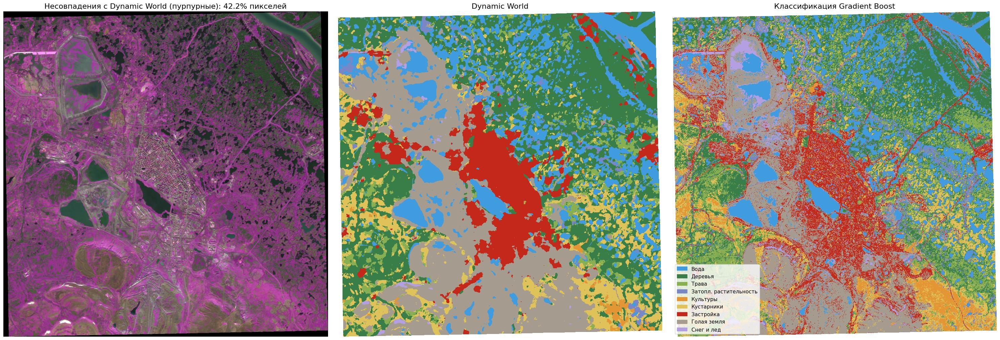

In [18]:
from scipy import ndimage

# Лучшая модель, обученная заново на всей выборке
final_model = classifiers[best_name].train(features=samples, classProperty='class', inputProperties=FEATURES)
classified = composite.select(FEATURES).classify(final_model).rename('class')
export_georeferenced_raster(classified, roi, 'data/classification.tif', dtype='int16')
classification = read_raster('data/classification.tif')[0]
classification = np.where(valid, classification, -1)

# Доля совпадения с Dynamic World
same = valid & (classification == dw)
mismatch = valid & (classification != dw)
agreement = same.sum() / valid.sum()
print(f'Совпадение карты {best_name} с Dynamic World: {agreement:.1%} пикселей')

# Несовпадения на границах объектов: пиксель на границе, если в окне 3×3 карты DW есть другой класс
dw_filled = np.where(valid, dw, 0)
boundary = valid & ((ndimage.maximum_filter(dw_filled, size=3) != dw_filled) |
                    (ndimage.minimum_filter(dw_filled, size=3) != dw_filled))
print(f'Пиксели на границах классов DW: {boundary.sum() / valid.sum():.1%} территории, '
      f'на них приходится {(mismatch & boundary).sum() / mismatch.sum():.1%} несовпадений; '
      f'совпадение на границах {1 - (mismatch & boundary).sum() / boundary.sum():.1%}, '
      f'внутри однородных участков {1 - (mismatch & ~boundary).sum() / (valid & ~boundary).sum():.1%}')

# Площади классов по Dynamic World и по своей карте
areas = pd.DataFrame({
    'Dynamic World, га': np.bincount(dw[valid], minlength=9) * PIXEL_AREA_HA,
    f'{best_name}, га': np.bincount(classification[valid], minlength=9) * PIXEL_AREA_HA,
}, index=DW_NAMES)
areas['Разность, га'] = areas[f'{best_name}, га'] - areas['Dynamic World, га']
areas['Разность, %'] = 100 * areas['Разность, га'] / areas['Dynamic World, га']
# Доля пикселей класса DW, которые модель отнесла к тому же классу
areas['Совпадение с DW, %'] = [100 * (same & (dw == k)).sum() / max((valid & (dw == k)).sum(), 1) for k in range(9)]
display(areas.sort_values('Dynamic World, га', ascending=False).round(1))

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
highlight = rgb.copy()
highlight[mismatch] = 0.6 * highlight[mismatch] + 0.4 * np.array([1, 0, 1])
axes[0].imshow(highlight)
axes[0].set_title(f'Несовпадения с Dynamic World (пурпурные): {mismatch.sum() / valid.sum():.1%} пикселей', fontsize=16)
axes[1].imshow(np.ma.masked_less(dw, 0), cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[1].set_title('Dynamic World', fontsize=16)
axes[2].imshow(np.ma.masked_less(classification, 0), cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[2].set_title(f'Классификация {best_name}', fontsize=16)
axes[2].legend(handles=dw_legend, loc='lower left', fontsize=11)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вопрос:** Какова доля совпадения карт? Где сосредоточены несовпадения — на границах объектов, в каких-то конкретных типах местности? Площади каких классов различаются сильнее всего?

**Ответ:** Карта Gradient Boost совпадает с Dynamic World в **58,1 %** пикселей, в 41,9 % — нет.

**Где несовпадения.**
- **Границы объектов.** Пиксели на границах классов DW (окно 3×3 содержит другой класс) занимают 22,1 % территории, но на них приходится 32,6 % несовпадений. На границах карты совпадают в 38,0 % пикселей, внутри однородных участков — в 63,7 %. Границы важны, но две трети несовпадений лежат внутри участков.
- **Лесотундра на северо-востоке.** Мозаика «деревья — трава — кустарники — затопл. растительность»: модель даёт пёструю попиксельную карту, а DW — сглаженные пятна (DW использует пространственный контекст).
- **Склоны на юго-востоке.** Модель расширяет «культуры».
- **Промзона и город.** Путаются «застройка» и «голая земля».
- **Хвостохранилище и отвалы.** Модель местами ставит «снег и лёд».

**Площади различаются сильнее всего у:**
- деревьев: 5 629 → 3 515 га (−2 114 га, −38 %);
- травы: 1 141 → 2 403 га (+1 262 га, +111 %);
- затопл. растительности: 265 → 1 382 га (+1 117 га, +422 %);
- голой земли: 5 058 → 3 985 га (−1 073 га);
- культур: 164,5 → 873 га (+709 га, +431 %);
- снега и льда: 76,5 → 530 га (+454 га, +593 %).

**Почему.** Это следствие стратифицированной выборки: по 400 точек на класс делают все классы для модели «равновероятными». Поэтому модель переоценивает редкие классы (снег, культуры, затопл. растительность) и недооценивает крупные (деревья, голую землю).

**Вопрос:** Рассмотрите объекты, которые вы описали в гипотезах (таблица 2). К каким классам отнесли их Dynamic World и ваша модель? Может ли классификатор, обученный по разметке Dynamic World, выделить такие объекты как отдельный класс? Почему?

**Ответ:** Объекты из гипотез обе карты относят к имеющимся классам (таблица проверки гипотез в разделе 5.8, окна вокруг объектов):

| Объект | Dynamic World | Gradient Boost |
|---|---|---|
| Хвостохранилище | Голая земля 56 %, Вода 30 %, Деревья 8 % | Голая земля 46 %, Вода 22 %, **Снег и лёд 14 %** |
| Белая полоса у хвостохранилища | Застройка 44 %, Голая земля 24 %, Вода 20 % | **Снег и лёд 41 %**, Застройка 23 %, Вода 15 % |
| Бурый ступенчатый отвал | Голая земля 74 %, Кустарники 11 % | Голая земля 57 %, Застройка 17 % |
| Чёрный отвал к ЮВ от города | Голая земля 99 % | Голая земля 57 %, Застройка 28 %, Снег и лёд 12 % |
| Склоны на ЮВ | Кустарники 41 %, Деревья 26 %, **Культуры 14 %** | **Культуры 35 %**, Кустарники 24 %, Трава 21 % |

**Может ли классификатор выделить их отдельно? Нет.** Классификатор, обученный по разметке DW, может выдать только один из девяти её классов: в обучающей выборке нет меток «хвосты», «шлак», «отвал». Каждый такой объект он «раскладывает» по ближайшим классам. Причём ошибки DW модель не исправляет, а усиливает:
- «культуры» в тундре: 873 га против 164,5 у DW;
- светлые хвосты и белый материал в канале модель принимает за снег, потому что единственный яркий класс в её выборке — «снег и лёд».

Чтобы выделить такие объекты, нужна собственная разметка с новыми классами, а подсказать её может кластеризация (раздел 5).

### **4.7. Выводы по разделу 4**

Опишите, насколько точно модель воспроизводит Dynamic World при честной проверке, какие классы и признаки для неё важнее, и в чём главное ограничение обучения по готовой карте.

**Вывод:**
1. При честной пространственной проверке модели воспроизводят Dynamic World умеренно. Лучшая — **Gradient Boost**: общая точность 0,556, каппа 0,500. Далее идут Random Forest (0,548 / 0,491), SVM (0,513 / 0,452), CART (0,479 / 0,414) и Min Distance (0,453 / 0,384). Случайная проверка завышает точность случайного леса лишь на 2 п. п. (0,567 против 0,548), потому что выборка разреженная (одна точка на 5,5 га). Для переноса на другие территории ориентироваться нужно на пространственную оценку.
2. **Надёжнее всего** распознаются вода (точность производителя 0,69), снег и лёд (0,67, точность пользователя 0,95) и голая земля (0,64). **Хуже всего** — кустарники (0,40 / 0,38), затопл. растительность и деревья: в лесотундре эти классы спектрально почти одинаковы.
3. **Признаки.** Важность распределена равномерно (7,3–8,2 % на признак). Каналы за пределами видимого диапазона и индексы дают 77 % суммарной важности, видимые — 23 %.
4. **Итоговая карта** совпадает с DW в 58,1 % пикселей. Из-за равных по классам выборок модель переоценивает редкие классы (снег +454 га, культуры +709 га) и недооценивает деревья (−2 114 га).
5. **Главное ограничение обучения по готовой карте:** модель повторяет легенду и ошибки разметки и не может выйти за пределы легенды. Хвостохранилище, отвалы, шлак и техногенная пустошь — главные объекты Норильска — остаются разложенными между «голой землёй», «водой», «застройкой» и даже «снегом», а «культуры» в тундре модель ещё и расширяет.

---

## **5. Кластеризация в Google Earth Engine: поиск того, чего нет в легенде**

Классификатор умеет только то, чему его научили: каждому пикселю он присваивает один из классов разметки. Кластеризация не знает никаких классов и группирует пиксели по сходству спектра. Если на территории есть объекты, спектрально непохожие на всё остальное, они могут образовать собственный кластер — даже если в легенде для них нет класса и на снимке в естественных цветах они почти не видны.

### **5.1. Стандартизация признаков в GEE**

Кластеризовать будем по восьми признакам `LOCAL_BANDS`: шести каналам отражения и индексам NDVI и NDWI. Отражение меняется в пределах 0–0,6, а индексы — от −1 до 1, поэтому без масштабирования индексы определяли бы расстояния между пикселями сильнее каналов. Стандартизация приводит каждый признак к среднему 0 и стандартному отклонению 1: $z = (x - \mu) / \sigma$.

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 2.5** (масштабирование признаков); в GEE среднее и стандартное отклонение каналов по области даёт `image.reduceRegion(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), region, scale=..., bestEffort=True)`, ключи результата — `B2_mean`, `B2_stdDev` и т. д.

**Задание 5.1.** Допишите функцию `standardize(image, region)`: она рассчитывает по области средние и стандартные отклонения всех каналов (`scale=30` — для оценки статистик этого достаточно), возвращает стандартизированное изображение и два списка — средние и стандартные отклонения в порядке каналов. Получите `cluster_input, means, stds`.

In [19]:
def standardize(image, region):
    """Стандартизация каналов изображения по статистикам области: (x - среднее) / стандартное отклонение."""
    names = image.bandNames().getInfo()
    stats = image.reduceRegion(
        reducer=ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True),
        geometry=region, scale=30, crs=utm_crs(region), bestEffort=True).getInfo()
    means = [stats[f'{name}_mean'] for name in names]
    stds = [stats[f'{name}_stdDev'] for name in names]
    standardized = (image.subtract(ee.Image.constant(means))
                    .divide(ee.Image.constant(stds))
                    .rename(names))
    return standardized, means, stds

cluster_input, means, stds = standardize(composite.select(LOCAL_BANDS), roi)
pd.DataFrame({'Среднее': means, 'Стандартное отклонение': stds}, index=pd.Index(LOCAL_BANDS, name='Признак')).round(4)

,Среднее,Стандартное отклонение
Признак,,
B2,0.0549,0.0277
B3,0.0711,0.0277
B4,0.0698,0.0372
B8,0.1627,0.0873
B11,0.1385,0.0597
B12,0.0998,0.0436
NDVI,0.3258,0.3130
NDWI,-0.3041,0.2993


### **5.2. K-средних на серверах GEE при разных K**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 3.5** (`ee.Clusterer.wekaKMeans`, `train`, `cluster`).

Число кластеров заранее неизвестно. При малом $K$ редкие объекты «прилипают» к крупным кластерам, при большом — крупные однородные поверхности дробятся на части. Поэтому построим разбиения сразу для нескольких $K$ и сравним их.

**Задание 5.2.** Получите обучающую выборку `training` из `cluster_input` (10 000 пикселей, `scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Для `K_LIST = [6, 12, 18]` обучите `ee.Clusterer.wekaKMeans(nClusters=K, init=1, seed=42)` и кластеризуйте `cluster_input`. Объедините карты в одно изображение `clusters` с каналами `K6`, `K12`, `K18` (`ee.Image.cat`), покажите кластеры при $K = 12$ на интерактивной карте (`randomVisualizer()`) и экспортируйте `clusters` в `data/clusters.tif` (тип `int16`). Загрузите результат в массив `cluster_maps` (каналы — разные $K$).

In [20]:
K_LIST = [6, 12, 18]

# Обучающая выборка пикселей для K-средних
training = cluster_input.sample(region=roi, scale=SCALE, projection=utm_crs(roi),
                                numPixels=10000, seed=42, tileScale=4)
print(f'Пикселей в обучающей выборке: {training.size().getInfo()}')

cluster_layers = []
for k in K_LIST:
    clusterer = ee.Clusterer.wekaKMeans(nClusters=k, init=1, seed=42).train(training)   # init=1 — k-means++
    cluster_layers.append(cluster_input.cluster(clusterer).rename(f'K{k}'))
clusters = ee.Image.cat(cluster_layers)

map_clusters = geemap.Map()
map_clusters.add_basemap('Esri.WorldImagery')
map_clusters.centerObject(roi, 12)
map_clusters.addLayer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.3, 'gamma': 1.4}, f'Sentinel-2, лето {YEAR}')
map_clusters.addLayer(composite, {'bands': ['B12', 'B8', 'B4'], 'min': 0, 'max': 0.4}, 'B12-B8-B4', False)
map_clusters.addLayer(clusters.select('K12').randomVisualizer(), {}, 'Кластеры GEE, K = 12')
display(map_clusters)

export_georeferenced_raster(clusters, roi, 'data/clusters.tif', dtype='int16')
cluster_maps = read_raster('data/clusters.tif')
cluster_maps = np.where(valid, cluster_maps, -1)   # пиксели без данных — -1
for k, layer in zip(K_LIST, cluster_maps):
    print(f'K = {k}: кластеров на карте {len(np.unique(layer[valid]))}, '
          f'площади от {np.bincount(layer[valid]).min() * PIXEL_AREA_HA:.1f} до {np.bincount(layer[valid]).max() * PIXEL_AREA_HA:.1f} га')

Пикселей в обучающей выборке: 10000


Map(center=[69.34998106248189, 88.20033996158713], controls=(WidgetControl(options=['position', 'transparent_b…

  0%|          |0/108 tiles [00:00<?]

K = 6: кластеров на карте 6, площади от 1093.7 до 5623.8 га
K = 12: кластеров на карте 12, площади от 36.8 до 3723.9 га
K = 18: кластеров на карте 18, площади от 29.5 до 2884.0 га


### **5.3. Площади и спектральные профили кластеров**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **разделы 3.3–3.4** (спектральные профили, состав кластеров по Dynamic World).

Кроме профилей, оценим **необычность** каждого кластера — расстояние от его центроида до «среднего» пикселя территории в пространстве стандартизированных признаков. После стандартизации средний пиксель находится в начале координат, поэтому необычность — это просто длина вектора центроида: $\lVert c_k
Vert = \sqrt{\sum_j c_{kj}^2}$. Кластеры фоновых поверхностей, занимающих большую часть территории, лежат близко к среднему, а спектрально непохожие на фон группы — далеко от него, независимо от их площади. Центроиды кластеров GEE вычислим сами: это средние стандартизированные признаки пикселей каждого кластера.

**Задание 5.3.** Для разбиения с $K = 12$ (`labels = cluster_maps[1]`):
- стандартизируйте признаки пикселей `pixels` теми же `means` и `stds`, что и в GEE (массив `z`), и рассчитайте центроиды кластеров `centroids` (форма $(K, 8)$);
- постройте таблицу `profiles`: для каждого кластера — площадь (га), доля площади (%), необычность и средние значения восьми признаков `LOCAL_BANDS` (по массиву `bands`); отсортируйте её по площади;
- покажите карту кластеров рядом со снимком и график спектральных профилей шести каналов (по оси X — каналы, по оси Y — среднее отражение, по линии на кластер).

In [21]:
K = 12
labels = cluster_maps[K_LIST.index(K)]
cluster_colors = plt.cm.tab20(np.linspace(0, 1, 20))[:K]
cluster_cmap = ListedColormap(cluster_colors)

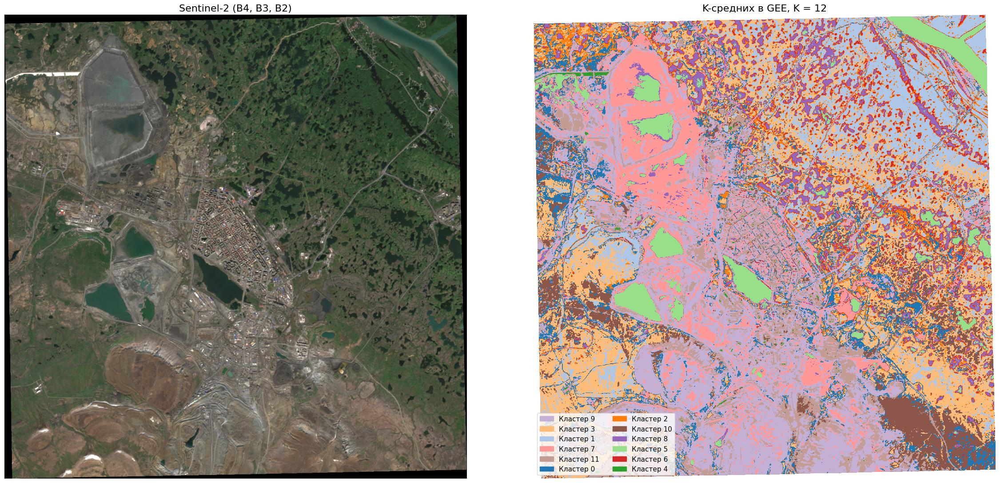

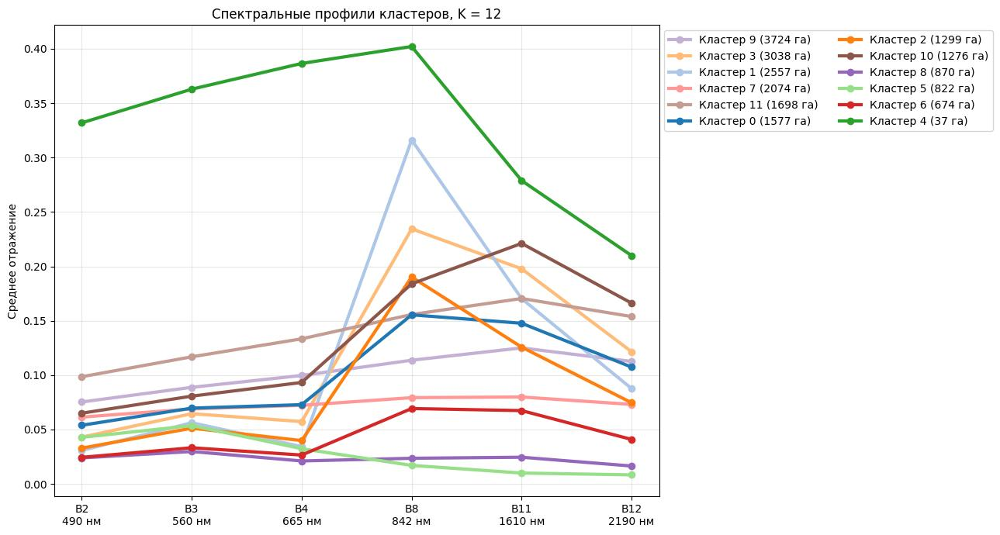

,"Площадь, га","Доля площади, %",Необычность,B2,B3,B4,B8,B11,B12,NDVI,NDWI
Кластер,,,,,,,,,,,
9,3723.87,18.955,1.758,0.075,0.089,0.100,0.114,0.125,0.113,0.066,-0.126
3,3038.28,15.466,1.954,0.043,0.065,0.057,0.234,0.198,0.122,0.604,-0.566
1,2557.19,13.017,3.074,0.031,0.056,0.034,0.316,0.170,0.088,0.802,-0.696
7,2074.05,10.557,1.926,0.061,0.069,0.072,0.079,0.080,0.073,0.048,-0.071
11,1698.01,8.643,3.294,0.099,0.117,0.133,0.156,0.170,0.154,0.079,-0.147
0,1576.83,8.026,0.383,0.054,0.070,0.073,0.155,0.148,0.107,0.361,-0.379
2,1298.90,6.612,2.040,0.033,0.051,0.040,0.190,0.126,0.075,0.652,-0.572
10,1276.03,6.495,2.243,0.065,0.081,0.093,0.184,0.221,0.166,0.330,-0.391
8,869.93,4.428,4.209,0.024,0.030,0.021,0.024,0.025,0.016,0.077,0.126


In [22]:
pixels = bands[:, valid].T                                   # (пиксели, 8 признаков LOCAL_BANDS)
z = (pixels - np.array(means)) / np.array(stds)              # стандартизация теми же статистиками, что в GEE
labels_valid = labels[valid]

# Центроиды кластеров GEE в пространстве стандартизированных признаков и их «необычность»
centroids = np.array([z[labels_valid == k].mean(axis=0) for k in range(K)])   # форма (K, 8)
unusualness = np.linalg.norm(centroids, axis=1)
cluster_areas = np.bincount(labels_valid, minlength=K) * PIXEL_AREA_HA

profiles = pd.DataFrame({
    'Площадь, га': cluster_areas,
    'Доля площади, %': 100 * cluster_areas / cluster_areas.sum(),
    'Необычность': unusualness,
}, index=pd.Index(range(K), name='Кластер'))
for j, band in enumerate(LOCAL_BANDS):
    profiles[band] = [pixels[labels_valid == k, j].mean() for k in range(K)]
profiles = profiles.sort_values('Площадь, га', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(24, 11))
axes[0].imshow(rgb)
axes[0].set_title('Sentinel-2 (B4, B3, B2)', fontsize=16)
axes[1].imshow(np.ma.masked_less(labels, 0), cmap=cluster_cmap, vmin=-0.5, vmax=K - 0.5, interpolation='nearest')
axes[1].set_title(f'K-средних в GEE, K = {K}', fontsize=16)
axes[1].legend(handles=[Patch(color=cluster_colors[k], label=f'Кластер {k}') for k in profiles.index],
               loc='lower left', fontsize=11, ncol=2)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

SPECTRAL = LOCAL_BANDS[:6]
WAVELENGTHS = [490, 560, 665, 842, 1610, 2190]   # центральные длины волн каналов, нм
fig, ax = plt.subplots(figsize=(13, 7))
for k in profiles.index:
    ax.plot(range(len(SPECTRAL)), profiles.loc[k, SPECTRAL], 'o-', color=cluster_colors[k], linewidth=3,
            label=f'Кластер {k} ({profiles.loc[k, "Площадь, га"]:.0f} га)')
ax.set_xticks(range(len(SPECTRAL)), [f'{b}\n{w} нм' for b, w in zip(SPECTRAL, WAVELENGTHS)])
ax.set_ylabel('Среднее отражение')
ax.set_title(f'Спектральные профили кластеров, K = {K}')
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=10, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

profiles.round(3)

### **5.4. Состав кластеров по Dynamic World и по своей классификации**

**Задание 5.4.** Постройте две таблицы сопряжённости, нормированные по строкам (%): кластер × класс Dynamic World (`dw`) и кластер × класс вашей классификации (`classification`). Строки упорядочите так же, как в `profiles` (по площади). Выведите их рядом в виде тепловых карт.

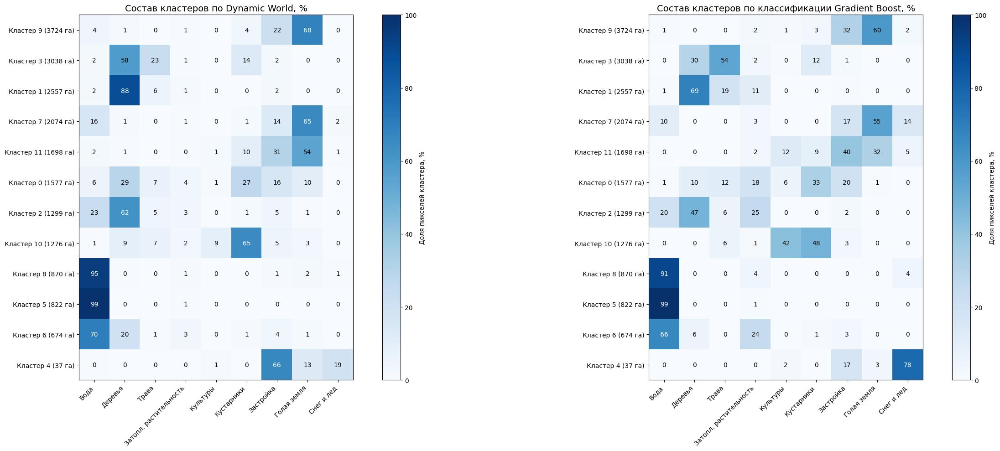

Состав по Dynamic World, %:


,Вода,Деревья,Трава,Затопл. растительность,Культуры,Кустарники,Застройка,Голая земля,Снег и лед
Кластер 9,4.1,1.0,0.3,0.6,0.1,3.8,21.7,68.0,0.4
Кластер 3,1.6,58.5,23.2,0.7,0.3,13.6,1.9,0.2,0.0
Кластер 1,2.0,88.5,6.0,1.3,0.1,0.1,2.0,0.0,0.0
Кластер 7,16.3,1.0,0.3,0.7,0.0,1.3,13.6,65.3,1.6
Кластер 11,2.1,0.6,0.2,0.5,1.2,9.7,30.6,54.3,0.7
Кластер 0,6.2,29.1,6.9,3.6,1.0,26.7,15.9,10.4,0.1
Кластер 2,23.1,62.4,4.5,3.5,0.0,1.3,4.5,0.7,0.0
Кластер 10,0.5,8.9,6.9,2.4,8.8,64.9,4.8,2.9,0.0
Кластер 8,94.9,0.5,0.0,0.9,0.0,0.0,1.3,1.7,0.7
Кластер 5,99.2,0.0,0.0,0.6,0.0,0.0,0.0,0.2,0.0


Состав по классификации Gradient Boost, %:


,Вода,Деревья,Трава,Затопл. растительность,Культуры,Кустарники,Застройка,Голая земля,Снег и лед
Кластер 9,0.5,0.0,0.2,1.9,0.9,2.9,32.0,59.7,1.8
Кластер 3,0.1,29.8,53.9,2.5,0.5,12.1,1.2,0.0,0.0
Кластер 1,0.7,68.7,18.7,11.3,0.3,0.0,0.4,0.0,0.0
Кластер 7,10.4,0.0,0.0,2.6,0.0,0.2,17.4,55.1,14.1
Кластер 11,0.1,0.0,0.0,2.4,12.1,8.6,39.6,32.1,5.1
Кластер 0,0.6,10.0,11.6,18.4,6.0,33.0,19.8,0.6,0.1
Кластер 2,20.0,47.4,5.6,25.1,0.0,0.1,1.9,0.0,0.0
Кластер 10,0.0,0.3,6.0,1.5,41.9,47.5,2.8,0.0,0.0
Кластер 8,90.9,0.0,0.0,4.5,0.0,0.0,0.2,0.0,4.4
Кластер 5,99.3,0.0,0.0,0.6,0.0,0.0,0.0,0.0,0.0


In [23]:
def composition(class_map, title):
    """Таблица кластер × класс (доля пикселей кластера, %), строки в порядке profiles."""
    table = pd.crosstab(labels_valid, class_map[valid], normalize='index') * 100
    table = table.reindex(index=profiles.index, columns=range(9), fill_value=0)
    table.columns = DW_NAMES
    table.index = [f'Кластер {k}' for k in profiles.index]
    return table

dw_composition = composition(dw, 'Dynamic World')
own_composition = composition(classification, best_name)

fig, axes = plt.subplots(1, 2, figsize=(26, 10))
for ax, table, title in zip(axes, [dw_composition, own_composition],
                            ['Состав кластеров по Dynamic World, %', f'Состав кластеров по классификации {best_name}, %']):
    im = ax.imshow(table.values, cmap='Blues', vmin=0, vmax=100)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f'{table.values[i, j]:.0f}', ha='center', va='center', fontsize=10,
                    color='white' if table.values[i, j] > 60 else 'black')
    ax.set_xticks(range(9), table.columns, rotation=45, ha='right')
    ax.set_yticks(range(K), [f'{name} ({profiles.loc[k, "Площадь, га"]:.0f} га)' for name, k in zip(table.index, profiles.index)])
    ax.set_title(title, fontsize=14)
    plt.colorbar(im, ax=ax, fraction=0.046, label='Доля пикселей кластера, %')
plt.tight_layout()
plt.show()

print('Состав по Dynamic World, %:')
display(dw_composition.round(1))
print(f'Состав по классификации {best_name}, %:')
display(own_composition.round(1))

**Задание 5.4 (продолжение).** По профилям, составу и виду на карте дайте названия всем кластерам и заполните таблицу. Названия — ваша интерпретация, а не результат алгоритма.

#### **Таблица 3. Интерпретация кластеров (K = 12)**

| Кластер | Площадь, га | Спектральный профиль | Состав по Dynamic World | Название |
|---|---|---|---|---|
| 9 | 3 724 | Плоский серый: 0,075–0,125 во всех каналах, NDVI 0,07 | Голая земля 68 %, Застройка 22 % | Техногенные грунты: промплощадки, дороги, отвалы, пустошь вокруг заводов |
| 3 | 3 038 | B8 0,23, NDVI 0,60, повышенный SWIR (B11 0,20) | Деревья 59 %, Трава 23 %, Кустарники 14 % | Редкостойная лесотундра и кустарниковая тундра |
| 1 | 2 557 | Максимальный ближний ИК (B8 0,32), NDVI 0,80, низкий SWIR | Деревья 89 % | Сомкнутые лиственничники и густые кустарники (долина реки на СВ) |
| 7 | 2 074 | Тёмный плоский: 0,06–0,08 во всех каналах, NDVI 0,05 | Голая земля 65 %, Вода 16 %, Застройка 14 % | Тёмные техногенные поверхности: хвосты в хвостохранилище, шлак, влажный грунт |
| 11 | 1 698 | Светлый плоский, растёт к SWIR: 0,10–0,17, NDVI 0,08 | Голая земля 54 %, Застройка 31 %, Кустарники 10 % | Светлые минеральные поверхности: крыши, бетон, щебень, сухие склоны отвалов |
| 0 | 1 577 | Средний: B8 0,155, B11 0,15, NDVI 0,36 | Деревья 29 %, Кустарники 27 %, Застройка 16 %, Голая земля 10 % | Переходные пиксели: края растительности, разреженная растительность на нарушенных землях |
| 2 | 1 299 | B8 0,19, NDVI 0,65, низкий SWIR (B12 0,075) | Деревья 62 %, Вода 23 % | Влажная растительность берегов озёр и заболоченных понижений |
| 10 | 1 276 | NDVI 0,33 при высоком SWIR (B11 0,22, B12 0,17) | Кустарники 65 %, Деревья 9 %, Культуры 9 %, Трава 7 % | Сухая горная кустарничковая тундра и угнетённая растительность (склоны на ЮВ и З) |
| 8 | 870 | Тёмный во всех каналах (≤ 0,03), NDWI 0,13 | Вода 95 % | Тёмная вода тундровых озёр и мелководий |
| 5 | 822 | Отражение падает от B3 (0,054) к SWIR (0,01), NDWI 0,52 | Вода 99 % | Мутная вода со взвесью: река, отстойники, озеро Долгое, вода хвостохранилища |
| 6 | 674 | Тёмный, B8 0,07, NDVI 0,44 | Вода 70 %, Деревья 20 % | Зарастающие мелководья и смешанные пиксели «вода + растительность» |
| 4 | 37 | Очень яркий: 0,33–0,40 в видимых и B8, спад к SWIR (B11 0,28, B12 0,21) | Застройка 66 %, Снег и лёд 19 %, Голая земля 13 % | Ярко-белые объекты: белый материал в канале, снежники, светлые крыши — «иголка» |

**Таблица 3:** заполнена выше. Кластеры делятся на четыре группы:
- **растительность** (1, 3, 2, 10, 0): 9 747 га, около 50 % территории;
- **вода** (5, 8, 6): 2 366 га;
- **техногенные поверхности** (9, 7, 11): 7 496 га, 38 %;
- **малый ярко-белый кластер 4**: 37 га.

Кластеризация сама, без разметки, разделила то, что DW смешивает:
- «голая земля» DW распалась на тёмные хвосты и шлак (7), серые техногенные грунты (9) и светлые минеральные поверхности (11);
- «деревья» DW — на сомкнутые лиственничники (1) и редкостойную лесотундру (3);
- «кустарники» и «культуры» DW на юго-востоке оказались одним кластером сухой тундры (10).

### **5.5. Необычные кластеры: «иголка в стоге сена»**

Первые кандидаты на интересные объекты — кластеры, далёкие от фона: алгоритм отвёл им собственный центроид, потому что их спектр не похож на спектр основной части территории. Часто это и самые маленькие кластеры, но не всегда: крупный карьер или большая гарь могут занимать сотни гектаров и всё же резко отличаться от окружающего леса, а несколько маленьких кластеров могут оказаться оттенками фона. Поэтому ориентируемся на необычность, а площадь учитываем при интерпретации.

In [24]:
#@title Готовая функция: фрагменты снимка с подсветкой пикселей маски
def zoom_views(mask, n=3, size=60, color=(1, 0, 0), title=''):
    """n фрагментов с наибольшей плотностью пикселей маски: снимок, B12-B8-B4 и подсветка."""
    step = 2 * size
    density = np.add.reduceat(np.add.reduceat(mask.astype(int), np.arange(0, H, step), axis=0), np.arange(0, W, step), axis=1)
    best = np.dstack(np.unravel_index(np.argsort(density.ravel())[::-1][:n], density.shape))[0]
    fig, axes = plt.subplots(3, n, figsize=(6 * n, 18))
    for j, (r, c) in enumerate(best):
        r = min(max(r * step + size, size), H - size)
        c = min(max(c * step + size, size), W - size)
        window = np.s_[r - size:r + size, c - size:c + size]
        highlight = rgb[window].copy()
        highlight[mask[window]] = color
        for i, img in enumerate([rgb[window], swir[window], highlight]):
            axes[i, j].imshow(img)
            axes[i, j].axis('off')
        axes[0, j].set_title(f'Фрагмент {j + 1}: строка {r}, столбец {c}')
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

**Задание 5.5.** Выведите три кластера с наибольшей необычностью с площадью и двумя главными классами Dynamic World и покажите для каждого карту расположения пикселей на снимке и фрагменты крупным планом (`zoom_views(labels == k, title=...)`). Затем выберите кластеры, которые вы считаете «иголками» — объектами, не имеющими своего класса в Dynamic World, — и запишите их номера в список `NEEDLES`.

,Необычность,"Площадь, га","Доля площади, %",Главные классы Dynamic World,Главные классы Gradient Boost
Кластер,,,,,
4,17.445,36.79,0.187,"Застройка 66%, Снег и лед 19%","Снег и лед 78%, Застройка 17%"
5,4.979,821.70,4.183,"Вода 99%, Затопл. растительность 1%","Вода 99%, Затопл. растительность 1%"
8,4.209,869.93,4.428,"Вода 95%, Голая земля 2%","Вода 91%, Затопл. растительность 4%"


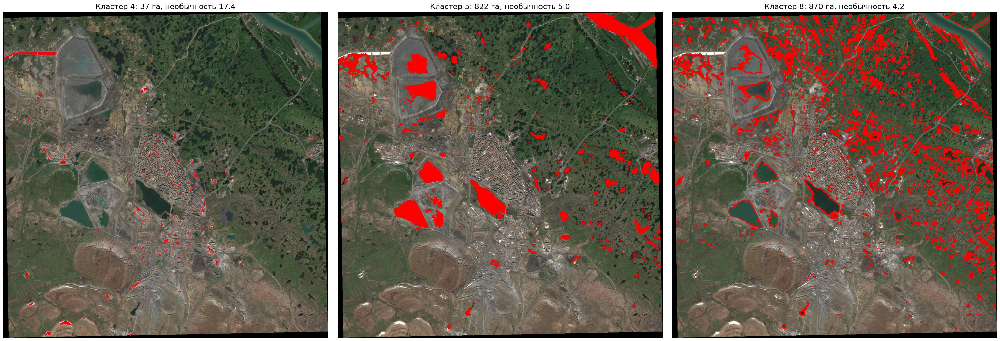

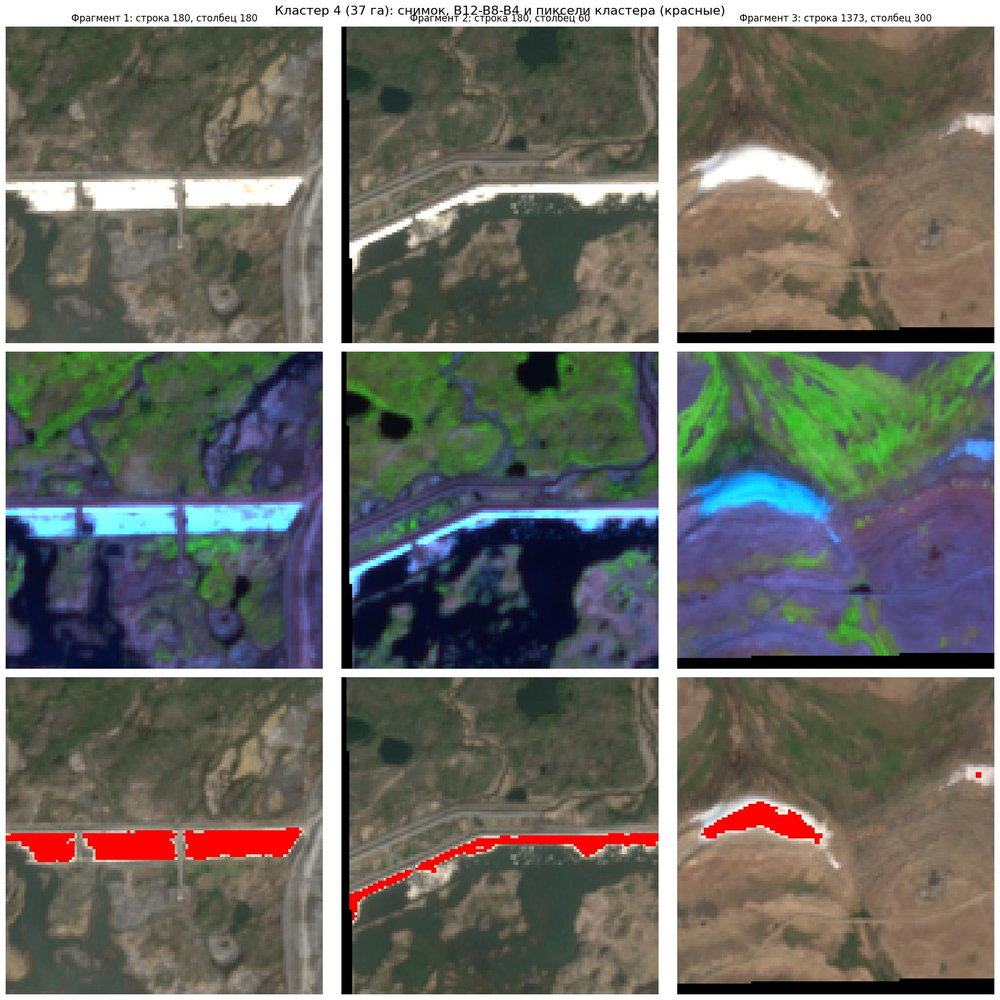

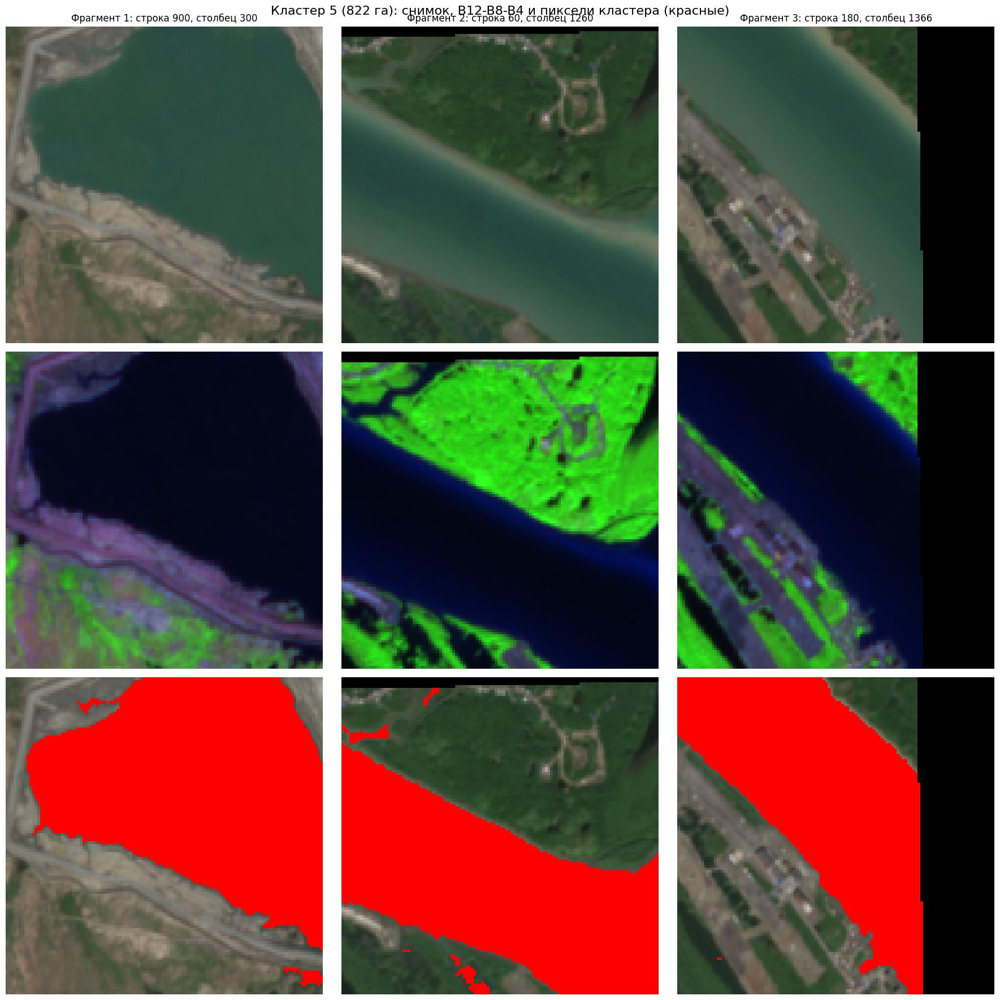

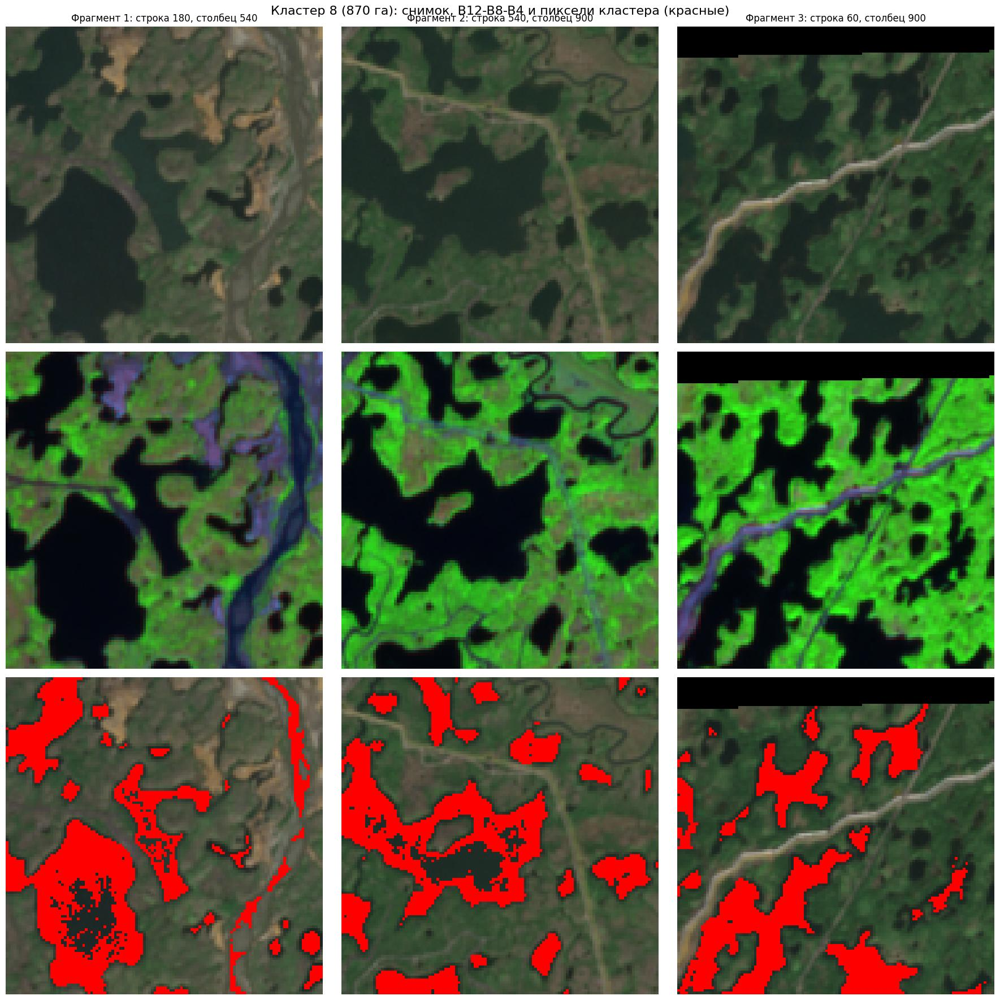

In [25]:
def top_classes(table, k, n=2):
    """n главных классов в составе кластера k: 'Класс 66%, Класс 19%'."""
    row = table.loc[f'Кластер {k}'].sort_values(ascending=False).head(n)
    return ', '.join(f'{name} {share:.0f}%' for name, share in row.items())

most_unusual = profiles.sort_values('Необычность', ascending=False).head(3)
summary = pd.DataFrame({
    'Необычность': most_unusual['Необычность'],
    'Площадь, га': most_unusual['Площадь, га'],
    'Доля площади, %': most_unusual['Доля площади, %'],
    'Главные классы Dynamic World': [top_classes(dw_composition, k) for k in most_unusual.index],
    f'Главные классы {best_name}': [top_classes(own_composition, k) for k in most_unusual.index],
})
display(summary.round(3))

# Расположение пикселей каждого кластера на снимке
fig, axes = plt.subplots(1, 3, figsize=(30, 10))
for ax, k in zip(axes, most_unusual.index):
    rows_k, cols_k = np.nonzero(labels == k)
    ax.imshow(rgb)
    ax.scatter(cols_k, rows_k, s=1, color='red')
    ax.set_title(f'Кластер {k}: {profiles.loc[k, "Площадь, га"]:.0f} га, необычность {profiles.loc[k, "Необычность"]:.1f}', fontsize=16)
    ax.axis('off')
plt.tight_layout()
plt.show()

for k in most_unusual.index:
    zoom_views(labels == k, title=f'Кластер {k} ({profiles.loc[k, "Площадь, га"]:.0f} га): снимок, B12-B8-B4 и пиксели кластера (красные)')

In [26]:
NEEDLES = [4]   # номера кластеров-«иголок»
needle_mask = np.isin(labels, NEEDLES) & valid

needle_area = needle_mask.sum() * PIXEL_AREA_HA
print(f'«Иголки» (кластеры {NEEDLES}): {needle_area:.1f} га, {needle_mask.sum() / valid.sum():.2%} площади территории')

def share_by_class(class_map, mask):
    """Состав пикселей маски по классам, %."""
    return pd.Series(np.bincount(class_map[mask], minlength=9) / mask.sum() * 100, index=DW_NAMES)

needle_composition = pd.DataFrame({'Dynamic World, %': share_by_class(dw, needle_mask),
                                   f'{best_name}, %': share_by_class(classification, needle_mask)})
display(needle_composition[needle_composition.sum(axis=1) > 0].round(1))

# Кластер 4 объединяет три группы объектов — разделим их по положению и по каналу B11
# (у снега отражение в коротковолновом ИК низкое, у светлых минеральных материалов и крыш — высокое)
rows_idx = np.arange(H)[:, None]
groups = {
    'Белый материал в канале у хвостохранилища': needle_mask & (rows_idx >= 140) & (rows_idx < 230) & (np.arange(W)[None, :] < 260),
    'Снежники на склонах (B11 < 0,15)': needle_mask & (bands[4] < 0.15),
}
groups['Прочие яркие поверхности (крыши, площадки)'] = needle_mask & ~groups['Белый материал в канале у хвостохранилища'] & ~groups['Снежники на склонах (B11 < 0,15)']
needle_groups = pd.DataFrame({
    name: {'Площадь, га': mask.sum() * PIXEL_AREA_HA,
           **{band: bands[j, mask].mean() for j, band in enumerate(LOCAL_BANDS[:6])},
           'Главный класс DW': DW_NAMES[np.bincount(dw[mask], minlength=9).argmax()],
           f'Главный класс {best_name}': DW_NAMES[np.bincount(classification[mask], minlength=9).argmax()]}
    for name, mask in groups.items()}).T
needle_groups

«Иголки» (кластеры [4]): 36.8 га, 0.19% площади территории


,"Dynamic World, %","Gradient Boost, %"
Вода,0.4,0.0
Культуры,1.0,2.3
Застройка,66.1,16.9
Голая земля,13.2,3.2
Снег и лед,19.4,77.6


,"Площадь, га",B2,B3,B4,B8,B11,B12,Главный класс DW,Главный класс Gradient Boost
Белый материал в канале у хвостохранилища,13.65,0.391414,0.434695,0.463256,0.470684,0.354593,0.201771,Застройка,Снег и лед
"Снежники на склонах (B11 < 0,15)",4.6,0.326526,0.341165,0.35874,0.358845,0.063227,0.05359,Снег и лед,Снег и лед
"Прочие яркие поверхности (крыши, площадки)",18.55,0.289552,0.31546,0.337033,0.3624,0.276527,0.254557,Застройка,Снег и лед


**Вопрос:** Что представляют собой выбранные кластеры? Опишите, как они выглядят на снимке в естественных цветах и в комбинации B12–B8–B4, их спектральный профиль, площадь и расположение. К каким классам их отнесли Dynamic World и ваша модель, и почему ни одна из карт не выделяет их отдельно?

**Ответ:** «Иголка» — кластер **4**: **36,8 га, 0,19 % территории**. Его необычность 17,4, в 3,5 раза больше, чем у любого другого кластера: у второго по необычности кластера 5 (вода) — 5,0. Кластеры 5 и 8 тоже далеки от фона, но это вода — для неё в DW есть класс.

**Состав кластера 4.** Он объединяет три группы ярко-белых объектов:
1. **Белый материал в канале у хвостохранилища — 13,7 га.** Прямая полоса ~2,3 км, разделённая перемычками, к западу от хвостохранилища. В естественных цветах она белая, как снег, в B12–B8–B4 — светло-голубая. Профиль: 0,39–0,47 в видимых каналах и B8, B11 = 0,35, B12 = 0,20. **Это не снег**: у настоящего снега отражение в коротковолновом ИК почти нулевое. Высокий B11 при провале в B12 характерен для влажного светлого минерального материала — по-видимому, это технологический осадок в картах намыва (например, известковые или гипсовые шламы).
2. **Снежники на склонах на юге — 4,6 га.** В естественных цветах белые, в B12–B8–B4 ярко-голубые. Профиль: B4 0,36, B8 0,36, B11 0,06, B12 0,05 — классический снег: яркий в видимом и почти чёрный в SWIR.
3. **Прочие яркие поверхности — 18,6 га.** Светлые крыши промышленных корпусов и площадки в городе и промзоне: плоский профиль, B11 0,28, B12 0,25.

**Как их классифицировали.** Dynamic World отнёс кластер к застройке (66 %), снегу (19 %) и голой земле (13 %), наша модель — к снегу и льду (77 %) и застройке (15 %).

**Почему ни одна карта не выделяет их отдельно.** В легенде нет класса для светлого технологического материала. DW, опираясь на контекст (прямые линии, соседство с промзоной), называет канал «застройкой». Наша модель смотрит только на спектр, а единственный яркий класс в её обучающей выборке — «снег и лёд», поэтому всё яркое она называет снегом. Так она ошибается так же, как глаз на снимке в естественных цветах.

Различает эти объекты только канал B11, но при K = 12 кластеризация объединяет их по общей яркости. Их разделение по SWIR видно уже по средним профилям групп.

### **5.6. Как число кластеров меняет найденное**

**Задание 5.6.** Для каждого $K$ из `K_LIST` выведите три самых необычных кластера: необычность, площадь, доля площади, доля пикселей кластера, входящих в ваши «иголки» при $K = 12$ (`needle_mask`), и доля всех «иголок», попавших в этот кластер. Так видно, при каком $K$ интересующие вас объекты выделяются в отдельные кластеры и как они дробятся при большом $K$.

In [27]:
rows = []
for k_value, layer in zip(K_LIST, cluster_maps):
    lab = layer[valid]
    cents = np.array([z[lab == c].mean(axis=0) for c in range(k_value)])
    unusual_k = np.linalg.norm(cents, axis=1)
    sizes = np.bincount(lab, minlength=k_value)
    needles_valid = needle_mask[valid]
    for c in np.argsort(unusual_k)[::-1][:3]:
        in_cluster = lab == c
        rows.append({
            'K': k_value, 'Кластер': c,
            'Необычность': unusual_k[c],
            'Площадь, га': sizes[c] * PIXEL_AREA_HA,
            'Доля площади, %': 100 * sizes[c] / sizes.sum(),
            'Доля пикселей кластера в «иголках», %': 100 * needles_valid[in_cluster].mean(),
            'Доля «иголок» в кластере, %': 100 * (needles_valid & in_cluster).sum() / needles_valid.sum(),
            'Главный класс DW': DW_NAMES[np.bincount(dw[valid][in_cluster], minlength=9).argmax()],
        })
by_k = pd.DataFrame(rows).set_index(['K', 'Кластер'])

# Куда попадают пиксели «иголок» при каждом K (все кластеры, а не только три самых необычных)
spread = {}
for k_value, layer in zip(K_LIST, cluster_maps):
    counts = pd.Series(np.bincount(layer[needle_mask], minlength=k_value) / needle_mask.sum() * 100)
    spread[f'K = {k_value}'] = ', '.join(f'кл. {c}: {v:.0f}%' for c, v in counts.sort_values(ascending=False).items() if v >= 1)
display(pd.Series(spread, name='Распределение «иголок» по кластерам').to_frame())
by_k.round(2)

,Распределение «иголок» по кластерам
K = 6,"кл. 4: 92%, кл. 0: 8%"
K = 12,кл. 4: 100%
K = 18,"кл. 4: 80%, кл. 11: 14%, кл. 15: 6%"


Необычность  Площадь, га  Доля площади, %  \
K  Кластер                                              
6  5               4.83      1093.74             5.57   
   4               3.00      2154.77            10.97   
   2               2.80      2083.12            10.60   
12 4              17.44        36.79             0.19   
   5               4.98       821.70             4.18   
   8               4.21       869.93             4.43   
18 4              19.06        29.46             0.15   
   5               5.17       527.54             2.69   
   16              4.61       553.74             2.82   

            Доля пикселей кластера в «иголках», %  \
K  Кластер                                          
6  5                                         0.00   
   4                                         1.57   
   2                                         0.00   
12 4                                       100.00   
   5                                         0.00   
   8                                         0.00   
18 4                                       100.00   
   5                                         0.00   
   16                                        0.00   

            Доля «иголок» в кластере, % Главный класс DW  
K  Кластер                                                
6  5                               0.00             Вода  
   4                              92.23       Кустарники  
   2                               0.00             Вода  
12 4                             100.00        Застройка  
   5                               0.00             Вода  
   8                               0.00             Вода  
18 4                              80.08        Застройка  
   5                               0.00             Вода  
   16                              0.00             Вода

**Вопрос:** При каком наименьшем $K$ ваши объекты выделяются в собственный кластер? Что происходит с ними при $K = 6$ и при $K = 18$? Какое $K$ вы бы выбрали для поиска объектов этого типа на соседних территориях?

**Ответ:** Из рассмотренных значений наименьшее K, при котором «иголки» выделяются в собственный кластер, — **K = 12**. Кластер 4 (36,8 га) на 100 % состоит из «иголок» и содержит 100 % их пикселей.

**При K = 6** их нет среди отдельных кластеров. 92 % «иголок» растворяются в кластере 4 площадью 2 155 га (11 % территории; главный класс DW — «кустарники»), где они составляют всего 1,6 % пикселей; ещё 8 % уходят в кластер 0. При шести центроидах алгоритму выгоднее «потратить» их на крупные облака точек (вода, лес, тундра, техногенный грунт), чем на 37 га ярких пикселей.

**При K = 18** самый необычный кластер (необычность 19,1) по-прежнему состоит только из «иголок», но он меньше — 29,5 га. В нём 80 % «иголок», а более тусклые части (края объектов, светлые крыши) уходят в кластеры 11 (14 %) и 15 (6 %). При большом K ядро становится чище, а объект дробится.

**Какое K выбрать для соседних территорий.** Я бы выбрал **K = 18** (по крайней мере 12–18). На другой территории больше разнообразных поверхностей, и при K = 12 центроиды могут уйти на них. При K = 18 яркие техногенные материалы гарантированно получают свой кластер, а раздробленные части легко собрать по необычности.

### **5.7. Необычные пиксели вне кластеров**

Отдельные необычные объекты не образуют своего кластера, но их пиксели находятся далеко от всех центроидов (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 5.3**). Центроиды `centroids` уже рассчитаны в разделе 5.3.

**Задание 5.7.** Рассчитайте расстояние от каждого пикселя до ближайшего центроида и карту `distance_map`. Найдите 0,1% самых далёких пикселей среди пикселей, не входящих в `NEEDLES`, покажите их на снимке и крупным планом. Определите, что это за объекты.

Доля «иголок» среди 0,1% самых далёких от центроидов пикселей всей территории: 52%
Порог расстояния: 6.22 (медиана по территории 0.84); необычных пикселей вне «иголок»: 1961 (19.6 га)


,B2,B3,B4,B8,B11,B12,NDVI,NDWI
Среднее у необычных,0.212,0.223,0.239,0.264,0.171,0.167,0.054,-0.089
Среднее по территории,0.055,0.071,0.070,0.163,0.138,0.100,0.322,-0.300


Состав необычных пикселей по Dynamic World, %: Застройка 51, Снег и лед 35, Голая земля 11, Вода 2
Ближайший кластер необычных пикселей, %: 11: 79, 9: 11, 10: 9


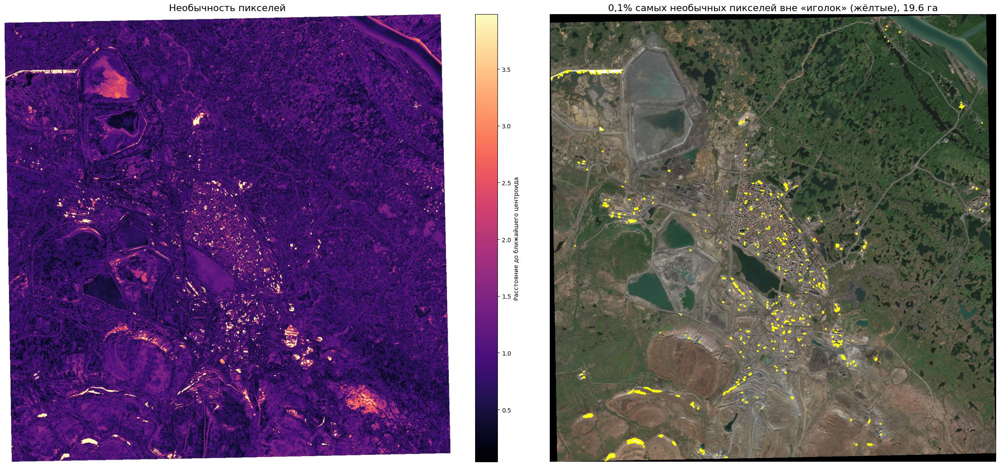

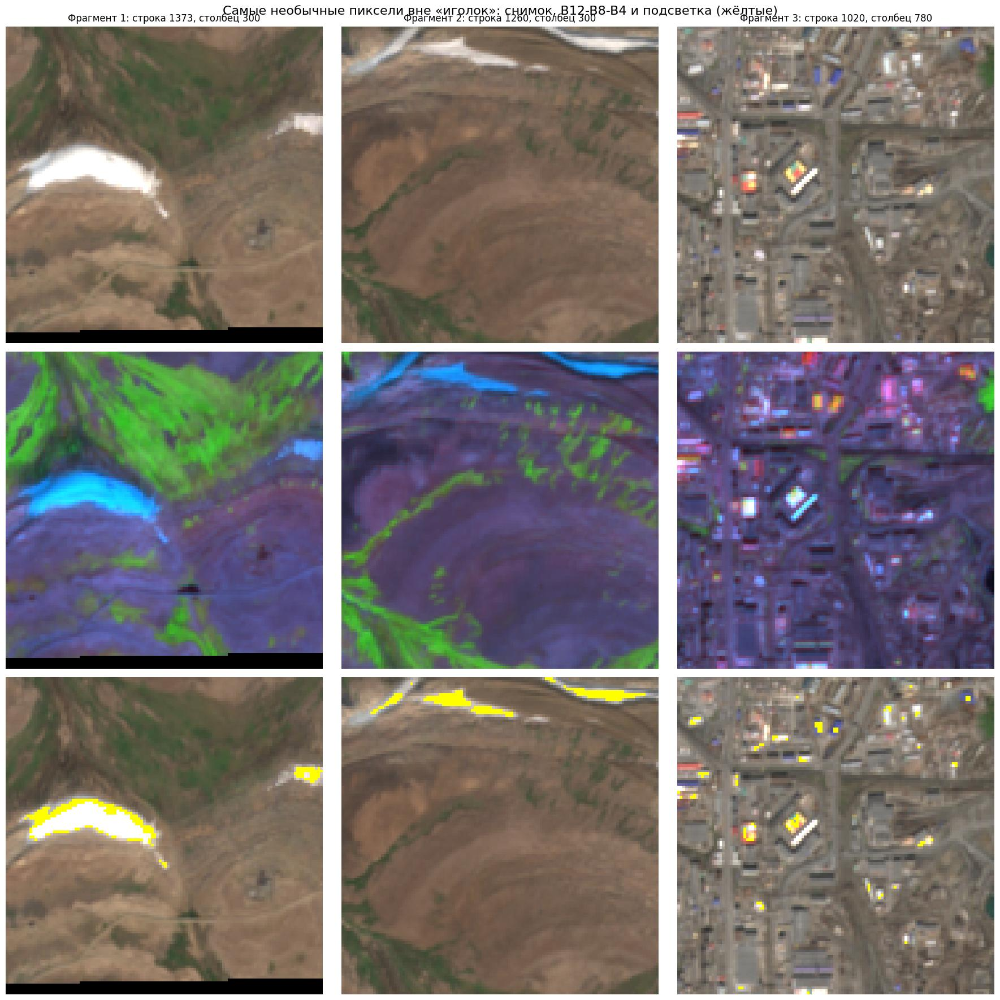

In [28]:
# Совет: квадраты расстояний всех пикселей до всех центроидов без больших промежуточных массивов:
# (z ** 2).sum(axis=1)[:, None] - 2 * z @ centroids.T + (centroids ** 2).sum(axis=1)[None]
squared = (z ** 2).sum(axis=1)[:, None] - 2 * z @ centroids.T + (centroids ** 2).sum(axis=1)[None]
nearest_distance = np.sqrt(np.maximum(squared.min(axis=1), 0))   # расстояние до ближайшего центроида
distance_map = np.full((H, W), np.nan)
distance_map[valid] = nearest_distance

top_all = distance_map > np.nanpercentile(distance_map, 99.9)
print(f'Доля «иголок» среди 0,1% самых далёких от центроидов пикселей всей территории: {needle_mask[top_all].mean():.0%}')

# Ищем необычное среди остальных пикселей: «иголки» исключаем
candidates = np.where(needle_mask, np.nan, distance_map)
threshold = np.nanpercentile(candidates, 99.9)
unusual = candidates > threshold
print(f'Порог расстояния: {threshold:.2f} (медиана по территории {np.nanmedian(distance_map):.2f}); '
      f'необычных пикселей вне «иголок»: {unusual.sum()} ({unusual.sum() * PIXEL_AREA_HA:.1f} га)')

unusual_table = pd.DataFrame({
    'Среднее у необычных': bands[:, unusual].mean(axis=1),
    'Среднее по территории': bands[:, valid].mean(axis=1),
}, index=LOCAL_BANDS)
display(unusual_table.T.round(3))
print('Состав необычных пикселей по Dynamic World, %:',
      ', '.join(f'{n} {v:.0f}' for n, v in share_by_class(dw, unusual).sort_values(ascending=False).items() if v >= 1))
print('Ближайший кластер необычных пикселей, %:',
      ', '.join(f'{k}: {v:.0f}' for k, v in pd.Series(labels[unusual]).value_counts(normalize=True).mul(100).items() if v >= 1))

fig, axes = plt.subplots(1, 2, figsize=(24, 11))
im = axes[0].imshow(distance_map, cmap='magma', vmax=np.nanpercentile(distance_map, 99.5))
plt.colorbar(im, ax=axes[0], fraction=0.046, label='Расстояние до ближайшего центроида')
axes[0].set_title('Необычность пикселей', fontsize=16)
axes[1].imshow(rgb)
rows_u, cols_u = np.nonzero(unusual)
axes[1].scatter(cols_u, rows_u, s=3, color='yellow')
axes[1].set_title(f'0,1% самых необычных пикселей вне «иголок» (жёлтые), {unusual.sum() * PIXEL_AREA_HA:.1f} га', fontsize=16)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

zoom_views(unusual, color=(1, 1, 0), title='Самые необычные пиксели вне «иголок»: снимок, B12-B8-B4 и подсветка (жёлтые)')

**Вопрос:** Что оказалось среди самых необычных пикселей? Это отдельные объекты, границы между разными поверхностями или артефакты композита (остатки облаков, теней)? Есть ли среди них объекты, которые вы пропустили бы при просмотре снимка?

**Ответ:** Среди 0,1 % самых далёких от центроидов пикселей всей территории 52 % — это сами «иголки». Вне «иголок» порог расстояния 6,22 (медиана по территории 0,84) отбирает 1 961 пиксель (**19,6 га**). По DW это застройка (51 %), снег и лёд (35 %) и голая земля (11 %); 79 % из них ближе всего к кластеру 11 (светлые поверхности).

На фрагментах видно, что это:
1. **Границы «иголок»** — смешанные пиксели по краям снежников и белого канала: снег или белый материал плюс грунт. Такой спектр не похож ни на один центроид.
2. **Узкие полосы снега** вдоль бровок отвалов и в промоинах на юге (фрагменты 1–2). Ширина у них 1–3 пикселя, поэтому собственного кластера они не образуют. Это отдельные объекты: в естественных цветах они почти сливаются со светлыми откосами отвалов, и при просмотре снимка я бы их пропустил.
3. **Цветные крыши** в городе (фрагмент 3): красные, жёлтые, синие и очень светлые. Их мало, а спектр необычен: высокое отражение в одном видимом канале при низком в других.

**Артефактов композита нет.** На карте необычности нет пятен облачной формы, а 27 снимков с маской SCL дали чистый композит. Повышенная, но ниже порога необычность видна также у бирюзовой воды верхней секции хвостохранилища и на склонах юго-востока.

### **5.8. Проверка гипотез и выводы по разделу 5**

**Задание 5.8.** Вернитесь к таблице 2. Для каждой гипотезы укажите, подтвердилась ли она, каким кластером или каким способом найден объект, его площадь и класс Dynamic World.

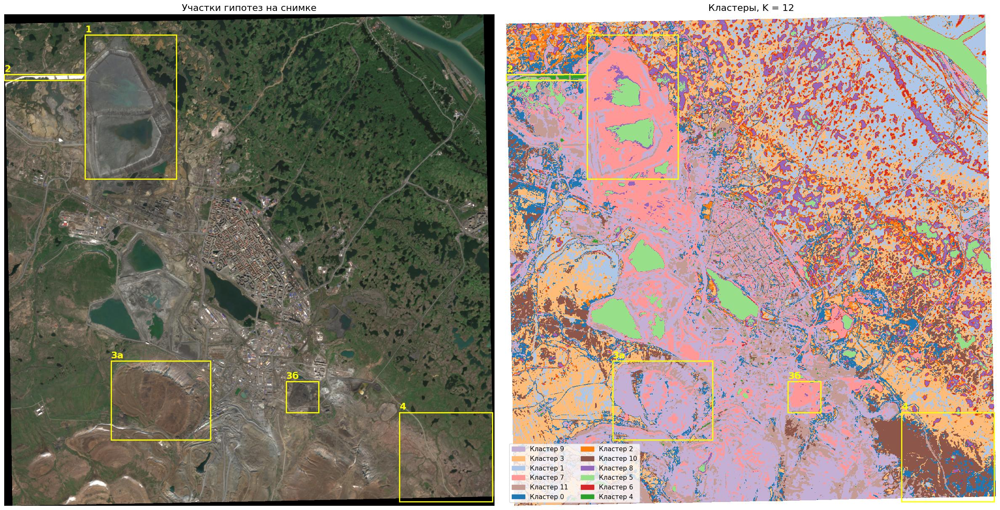

,"Площадь окна, га",Кластеры K = 12,Dynamic World,Gradient Boost,NDVI,B11
Участок,,,,,,
1. Хвостохранилище (СЗ),1113.00,"7 49%, 9 16%, 5 12%","Голая земля 56%, Вода 30%, Деревья 8%","Голая земля 46%, Вода 22%, Снег и лед 14%",0.059,0.081
2. Белая полоса западнее хвостохранилища,39.44,"4 32%, 9 24%, 11 20%","Застройка 44%, Голая земля 24%, Вода 20%","Снег и лед 40%, Застройка 24%, Вода 15%",0.030,0.204
3а. Бурый ступенчатый отвал (Ю),667.00,"9 56%, 7 14%, 11 13%","Голая земля 74%, Кустарники 11%, Вода 5%","Голая земля 56%, Застройка 17%, Кустарники 10%",0.126,0.134
3б. Чёрный отвал к ЮВ от города,85.50,"7 69%, 9 23%, 11 5%","Голая земля 99%, Застройка 1%, Трава 0%","Голая земля 57%, Застройка 28%, Снег и лед 11%",0.045,0.084
4. Склоны на ЮВ («Культуры» в DW),670.79,"10 47%, 3 27%, 0 13%","Кустарники 41%, Деревья 26%, Культуры 14%","Культуры 36%, Кустарники 24%, Трава 21%",0.380,0.202


In [29]:
# Проверка гипотез таблицы 2: окна (строки, столбцы растра) вокруг описанных объектов
import matplotlib.patches as mpatches

HYPOTHESIS_WINDOWS = {
    '1. Хвостохранилище (СЗ)': np.s_[60:480, 235:500],
    '2. Белая полоса западнее хвостохранилища': np.s_[175:192, 0:235],
    '3а. Бурый ступенчатый отвал (Ю)': np.s_[1010:1240, 310:600],
    '3б. Чёрный отвал к ЮВ от города': np.s_[1070:1160, 820:915],
    '4. Склоны на ЮВ («Культуры» в DW)': np.s_[1160:1420, 1150:1420],
}

def top_shares(values, names=None, n=3):
    """n самых частых значений массива с долями, %."""
    shares = pd.Series(values).value_counts(normalize=True).mul(100).head(n)
    return ', '.join(f'{names[v] if names else v} {s:.0f}%' for v, s in shares.items())

rows = []
for name, win in HYPOTHESIS_WINDOWS.items():
    m = np.zeros((H, W), bool)
    m[win] = True
    m &= valid
    rows.append({
        'Участок': name,
        'Площадь окна, га': m.sum() * PIXEL_AREA_HA,
        'Кластеры K = 12': top_shares(labels[m]),
        'Dynamic World': top_shares(dw[m], DW_NAMES),
        best_name: top_shares(classification[m], DW_NAMES),
        'NDVI': bands[6, m].mean(),
        'B11': bands[4, m].mean(),
    })
hypotheses_check = pd.DataFrame(rows).set_index('Участок')

fig, axes = plt.subplots(1, 2, figsize=(24, 12))
axes[0].imshow(rgb)
axes[0].set_title('Участки гипотез на снимке', fontsize=16)
axes[1].imshow(np.ma.masked_less(labels, 0), cmap=cluster_cmap, vmin=-0.5, vmax=K - 0.5, interpolation='nearest')
axes[1].set_title(f'Кластеры, K = {K}', fontsize=16)
axes[1].legend(handles=[Patch(color=cluster_colors[k], label=f'Кластер {k}') for k in profiles.index],
               loc='lower left', fontsize=11, ncol=2)
for ax in axes:
    for name, win in HYPOTHESIS_WINDOWS.items():
        ax.add_patch(mpatches.Rectangle((win[1].start, win[0].start), win[1].stop - win[1].start,
                                        win[0].stop - win[0].start, fill=False, color='yellow', linewidth=2))
        ax.text(win[1].start, win[0].start - 8, name.split('.')[0], color='yellow', fontsize=16, fontweight='bold')
    ax.axis('off')
plt.tight_layout()
plt.show()

hypotheses_check.round(3)

**Ответ:** Проверка по окнам вокруг объектов (таблица выше):

1. **Хвостохранилище — подтвердилась.** В окне 1 113 га кластер 7 занимает 49 %, кластер 9 — 16 %, кластер 5 (мутная вода) — 12 %. Хвосты попали в кластер тёмных пикселей с плоским профилем (0,06–0,08, NDVI в окне 0,06). DW делит окно на голую землю (56 %) и воду (30 %), модель добавляет ещё 14 % «снега». Хвосты — не малая «иголка», а крупный кластер: кластер 7 в целом занимает 2 074 га, 10,6 % территории.
2. **Белая полоса — гипотеза «снег/наледь» не подтвердилась.** Объект найден кластером-«иголкой» 4 (32 % окна, 13,7 га белого материала). Его B11 = 0,35 при 0,06 у настоящих снежников, так что это светлый влажный технологический материал, а не снег. DW: застройка 44 %, модель: снег и лёд 41 %. Модель ошибается так же, как я при взгляде на снимок в естественных цветах.
3. **Отвалы и шлак — подтвердилась.**
   - Бурый ступенчатый отвал (окно 667 га): кластер 9 — 56 %, 7 — 14 %, 11 — 13 %; NDVI 0,13; DW: голая земля 74 %.
   - Чёрный отвал (85,5 га): кластер 7 — 69 %, то есть в одном кластере с хвостами, как и предполагалось; DW: голая земля 99 %.
   - Отдельного «кластера отвалов» нет: по спектру отвалы совпадают с другими минеральными поверхностями, а распознаются по форме — террасам и плоскому верху.
4. **Склоны на юго-востоке — подтвердилась.** Кластер 10 занимает 47 % окна (670,8 га), кластер 3 — 27 %. NDVI 0,38 при высоком B11 = 0,20 — разреженная сухая растительность. DW называет окно кустарниками (41 %), деревьями (26 %) и культурами (14 %). Модель усиливает ошибку: «культуры» у неё занимают 35 % окна и 873 га по всей карте. Весь кластер 10 (1 276 га) — это сухая тундра, которую DW делит между кустарниками (65 %) и культурами (9 %).

Опишите, что нашла кластеризация из того, чего нет в легенде Dynamic World и что не выделил ваш классификатор; какие объекты плохо видны в естественных цветах, но выделяются по инфракрасным каналам; как выбор $K$ влияет на результат.

**Вывод:**
1. **Что нашла кластеризация из отсутствующего в легенде.** K-средних без разметки выделил то, для чего в Dynamic World нет классов и чего не выделил классификатор:
   - **тёмные хвосты и шлак** (кластер 7, 2 074 га) отдельно от серых техногенных грунтов (9, 3 724 га) и светлых минеральных поверхностей (11, 1 698 га) — DW называет всё это «голой землёй» и «застройкой»;
   - **сухую горную тундру** (кластер 10, 1 276 га), которую DW частично называет «культурами»;
   - **«иголку»** — кластер 4 (36,8 га, 0,19 % территории, необычность 17,4 при ≤ 5,0 у остальных), объединяющий белый технологический материал в канале у хвостохранилища (13,7 га), летние снежники (4,6 га) и светлые крыши.
2. **Что видно только в инфракрасных каналах.** В естественных цветах белый материал в канале неотличим от снега, и классификатор называет его снегом. Различает их только канал B11: 0,35 у материала против 0,06 у снега. На комбинации B12–B8–B4 вся техногенная зона (хвосты, отвалы, промплощадки) резко отделяется от живой лесотундры. Узкие полосы снега вдоль бровок отвалов нашлись по расстоянию до центроидов: в естественных цветах они почти не видны.
3. **Как выбор K влияет на результат.** При K = 6 «иголки» растворены в кластере на 2 155 га (1,6 % его пикселей). При K = 12 они впервые получают собственный кластер со 100 % «иголок». При K = 18 ядро чище и меньше (29,5 га, 80 % «иголок»), а края уходят в соседние кластеры. Для поиска малых объектов нужно K больше, чем подсказывают метрики качества разбиения.

---

## **6. Сжатие изображений кластеризацией цветов (для бакалавров)**

Кластеризация цветов заменяет все цвета изображения палитрой из $K$ цветов — центроидов кластеров (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 6**). Выигрыш в размере получается, только если результат сохранён как **палитра + номера цветов пикселей**. В этом разделе вы проверите, для каких изображений и при каком числе цветов такое сжатие действительно выгодно по сравнению с обычными форматами.

### **6.1. Изображения для экспериментов**

**Задание 6.1.** Загрузите в папку `photos` (панель «Файлы» слева, папка создаётся следующей ячейкой) **две свои фотографии** в формате JPEG:
- фотографию с плавными переходами цвета — небо, портрет, пейзаж, животное на однородном фоне;
- фотографию с множеством мелких деталей и ярких цветов — рынок, цветник, городская улица.

Пропишите имена файлов в словаре `PHOTOS`. Кроме фотографий в эксперименты войдут два изображения вашей территории: фрагмент карты кластеров $K = 12$ из раздела 5 (тематическая карта с небольшим числом цветов) и тот же фрагмент снимка в естественных цветах. Все изображения уменьшаются так, чтобы большая сторона была не больше 1024 пикселей, — это ускоряет расчёты и делает изображения сопоставимыми.

In [30]:
os.makedirs('photos', exist_ok=True)

In [31]:
PHOTOS = {
    'Фото с плавными переходами': 'photos/tau.jpg',      # пейзаж с облачным небом и плавными градиентами
    'Фото с мелкими деталями': 'photos/waha40k.jpg',     # батальная сцена с множеством мелких ярких деталей
}

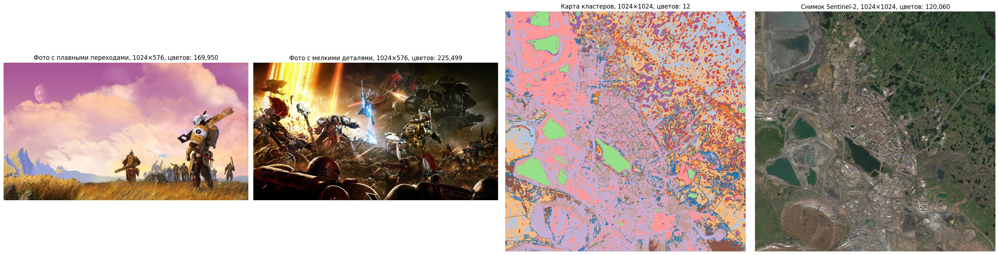

In [32]:
#@title Готовая функция: подготовка изображений
MAX_SIDE = 1024

def load_photo(path, max_side=MAX_SIDE):
    """RGB-массив фотографии, уменьшенной до max_side пикселей по большей стороне."""
    img = Image.open(path).convert('RGB')
    img.thumbnail((max_side, max_side))
    return np.array(img)

images = {name: load_photo(path) for name, path in PHOTOS.items()}

# Фрагмент территории: центральный квадрат растра не больше MAX_SIDE пикселей
side = min(H, W, MAX_SIDE)
r0, c0 = (H - side) // 2, (W - side) // 2
window = np.s_[r0:r0 + side, c0:c0 + side]
cluster_rgb = np.round(cluster_colors[:, :3] * 255).astype('uint8')   # цвета кластеров в RGB
images['Карта кластеров'] = cluster_rgb[np.clip(labels[window], 0, K - 1)]
images['Снимок Sentinel-2'] = (rgb[window] * 255).astype('uint8')

fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 7))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(f'{name}, {img.shape[1]}×{img.shape[0]}, цветов: {len(np.unique(img.reshape(-1, 3), axis=0)):,}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### **6.2. Как сохранять результат**

Размер файла — главный показатель эффективности сжатия, поэтому сохраняйте изображения **строго одним из способов из таблицы 4** и измеряйте размер **настоящего файла на диске** функцией `os.path.getsize`. Все файлы раздела сохраняйте в папку `compressed/<название изображения>/`.

#### **Таблица 4. Способы сохранения**

| **Способ** | **Код** | **Что записывается в файл** |
|---|---|---|
| PNG без потерь — эталон размера | `Image.fromarray(img).save(path, format='PNG', optimize=True)` | 3 байта цвета на пиксель, сжатие без потерь |
| JPEG, качество 90 — обычное сжатие фотографий | `Image.fromarray(img).save(path, format='JPEG', quality=90)` | Сжатие с потерями, рассчитанное на фотографии |
| **Палитровый PNG — результат кластеризации** | `p_img = Image.frombytes('P', (w, h), indices.astype('uint8').tobytes())`<br>`p_img.putpalette(palette.flatten().tolist())`<br>`p_img.save(path, format='PNG', optimize=True)` | Палитра из $K$ цветов и номер цвета для каждого пикселя: 1 бит на пиксель при 2 цветах, 4 бита при 16, 8 бит при 256 |

Обратите внимание:
- номера цветов `indices` должны иметь тип `uint8` (от 0 до 255), поэтому $K \le 256$;
- параметр `mode` функции `Image.fromarray` в новых версиях Pillow устарел, поэтому палитровое изображение создаётся через `Image.frombytes`;
- изображение `palette[indices]` (восстановленные цвета) нужно только для просмотра и расчёта качества — если сохранить его как RGB-PNG или JPEG, выигрыша от кластеризации не будет (это вы проверите в разделе 6.4).

**Задание 6.2.** Допишите две функции:
- `quantize_kmeans(image, k, sample_size=50000, seed=42)` — обучает `KMeans(n_clusters=k, n_init=1, random_state=seed)` на случайной подвыборке `sample_size` пикселей (все пиксели, если `sample_size=None` или пикселей меньше), относит все пиксели к ближайшим центроидам и возвращает палитру `palette` (`uint8`, форма $(k, 3)$), индексы `indices` (`uint8`, форма $(h, w)$) и время работы в секундах;
- `save_palette_png(palette, indices, path)` — сохраняет палитровый PNG по таблице 4 и возвращает размер файла в КБ.

In [33]:
def quantize_kmeans(image, k, sample_size=50000, seed=42):
    """Квантизация RGB-изображения до k цветов методом K-средних: палитра, индексы и время, с."""
    start = time.perf_counter()
    h_img, w_img, _ = image.shape
    colors = image.reshape(-1, 3).astype('float32')     # пиксели как массив (h*w, 3) типа float32
    if sample_size is None or sample_size >= len(colors):
        sample = colors                                  # все пиксели
    else:
        sample = colors[np.random.default_rng(seed).choice(len(colors), sample_size, replace=False)]
    kmeans = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(sample)
    palette = np.clip(np.round(kmeans.cluster_centers_), 0, 255).astype('uint8')   # центроиды — цвета палитры
    indices = kmeans.predict(colors).astype('uint8').reshape(h_img, w_img)        # номер цвета каждого пикселя
    return palette, indices, time.perf_counter() - start

def save_palette_png(palette, indices, path):
    """Палитровый PNG: таблица цветов и номер цвета каждого пикселя. Возвращает размер файла, КБ."""
    h_img, w_img = indices.shape
    p_img = Image.frombytes('P', (w_img, h_img), indices.astype('uint8').tobytes())
    p_img.putpalette(palette.flatten().tolist())
    p_img.save(path, format='PNG', optimize=True)
    return os.path.getsize(path) / 1024

In [34]:
#@title Готовые функции: сохранение без кластеризации и метрики качества
def save_rgb(img, path, **save_args):
    """Сохраняет RGB-массив в файл и возвращает размер, КБ."""
    Image.fromarray(img).save(path, **save_args)
    return os.path.getsize(path) / 1024

def quality(original, restored):
    """PSNR (дБ) и SSIM восстановленного изображения относительно исходного."""
    return (peak_signal_noise_ratio(original, restored, data_range=255),
            structural_similarity(original, restored, channel_axis=2, data_range=255))

for name in images:
    os.makedirs(f'compressed/{name}', exist_ok=True)

### **6.3. Размер, качество и время при разном числе цветов**

**Задание 6.3.** Для каждого изображения из `images`:
1. Сохраните эталоны без кластеризации: `compressed/<имя>/original.png` (PNG без потерь) и `compressed/<имя>/original_q90.jpg` (JPEG, качество 90). Для JPEG рассчитайте PSNR и SSIM относительно исходного изображения.
2. Для каждого `k` из `K_COLORS` выполните `quantize_kmeans`, сохраните палитровый PNG `compressed/<имя>/kmeans_<k>.png`, рассчитайте PSNR и SSIM восстановленного изображения `palette[indices]`.

Соберите две таблицы: `baselines` (столбцы `Изображение`, `PNG без потерь, КБ`, `JPEG 90, КБ`, `JPEG 90 PSNR`, `JPEG 90 SSIM`) и `results` (столбцы `Изображение`, `Цветов`, `Время, с`, `Палитровый PNG, КБ`, `PSNR`, `SSIM`). Сохраните палитры и индексы в словарь `quantized[(имя, k)]` — они понадобятся дальше. Если восстановленное изображение точно совпадает с исходным (так бывает, когда цветов в изображении не больше $K$), PSNR равен бесконечности.

In [35]:
K_COLORS = [2, 4, 8, 16, 32, 64, 128, 256]

In [36]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# В карте кластеров всего 12 цветов: при k > 12 K-средних находит меньше различных центроидов, чем k,
# и выдаёт предупреждение — на результат это не влияет (лишние цвета палитры просто не используются)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# «Прогрев»: первый вызов KMeans тратит ~2 с на разовую инициализацию библиотек,
# без него время первого замера было бы завышено
quantize_kmeans(next(iter(images.values())), 2)

baseline_rows, result_rows = [], []
quantized = {}
for name, img in images.items():
    folder = f'compressed/{name}'

    # 1. Эталоны без кластеризации
    png_kb = save_rgb(img, f'{folder}/original.png', format='PNG', optimize=True)
    jpg_kb = save_rgb(img, f'{folder}/original_q90.jpg', format='JPEG', quality=90)
    jpg_psnr, jpg_ssim = quality(img, np.array(Image.open(f'{folder}/original_q90.jpg').convert('RGB')))
    baseline_rows.append({'Изображение': name, 'PNG без потерь, КБ': png_kb, 'JPEG 90, КБ': jpg_kb,
                          'JPEG 90 PSNR': jpg_psnr, 'JPEG 90 SSIM': jpg_ssim})

    # 2. K-средних при разном числе цветов
    for k in K_COLORS:
        palette, indices, seconds = quantize_kmeans(img, k)
        path = f'{folder}/kmeans_{k}.png'
        size_kb = save_palette_png(palette, indices, path)
        restored = palette[indices]
        # Проверка: файл действительно хранит изображение palette[indices]
        assert np.array_equal(np.array(Image.open(path).convert('RGB')), restored)
        with np.errstate(divide='ignore'):          # при точном совпадении PSNR = бесконечность
            psnr, ssim = quality(img, restored)
        quantized[(name, k)] = (palette, indices)
        result_rows.append({'Изображение': name, 'Цветов': k, 'Время, с': seconds,
                            'Палитровый PNG, КБ': size_kb, 'PSNR': psnr, 'SSIM': ssim})

baselines = pd.DataFrame(baseline_rows).set_index('Изображение')
results = pd.DataFrame(result_rows)
display(baselines.round(3))
display(results.pivot(index='Цветов', columns='Изображение', values='PSNR').round(2).rename_axis(columns='PSNR, дБ'))
results.pivot(index='Цветов', columns='Изображение', values='SSIM').round(3).rename_axis(columns='SSIM')

,"PNG без потерь, КБ","JPEG 90, КБ",JPEG 90 PSNR,JPEG 90 SSIM
Изображение,,,,
Фото с плавными переходами,603.322,107.049,41.091,0.982
Фото с мелкими деталями,969.851,189.593,33.288,0.946
Карта кластеров,345.826,574.490,20.008,0.756
Снимок Sentinel-2,1805.941,297.824,37.280,0.959


"PSNR, дБ",Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,15.76,23.04,16.97,17.36
4,20.24,26.84,20.88,22.10
8,26.14,30.81,23.99,25.51
16,inf,33.26,26.79,28.45
32,inf,35.64,29.52,31.52
64,inf,37.84,32.16,34.29
128,inf,39.91,34.51,36.61
256,inf,41.75,36.68,38.81


SSIM,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,0.643,0.576,0.522,0.741
4,0.863,0.763,0.675,0.804
8,0.962,0.889,0.769,0.841
16,1.000,0.934,0.814,0.870
32,1.000,0.949,0.872,0.906
64,1.000,0.967,0.915,0.933
128,1.000,0.978,0.940,0.952
256,1.000,0.985,0.960,0.966


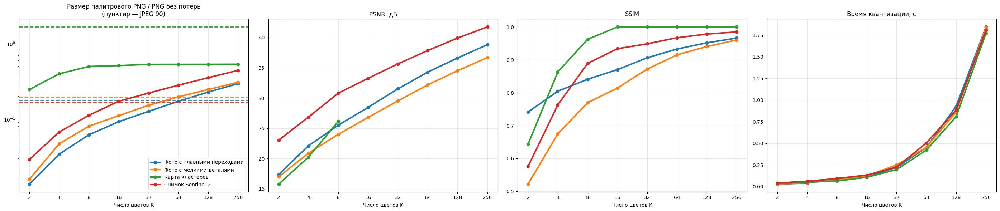

Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,0.04,0.04,0.03,0.03
4,0.05,0.06,0.05,0.04
8,0.07,0.09,0.07,0.09
16,0.11,0.13,0.12,0.11
32,0.20,0.23,0.25,0.22
64,0.42,0.50,0.46,0.45
128,0.81,0.89,0.86,0.93
256,1.77,1.81,1.84,1.85


Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,85.0,52.5,15.4,8.3
4,137.4,121.5,45.4,20.6
8,172.0,202.5,78.1,37.3
16,176.4,310.8,107.4,55.6
32,183.4,398.4,147.5,76.2
64,183.5,506.6,190.9,103.7
128,183.7,637.2,238.4,137.2
256,184.1,796.4,297.1,177.4


In [37]:
#@title Готовый код: графики размера, качества и времени
fig, axes = plt.subplots(1, 4, figsize=(28, 6))
for name, part in results.groupby('Изображение', sort=False):
    ratio = part['Палитровый PNG, КБ'] / baselines.loc[name, 'PNG без потерь, КБ']
    line, = axes[0].plot(part['Цветов'], ratio, 'o-', linewidth=3, label=name)
    axes[0].axhline(baselines.loc[name, 'JPEG 90, КБ'] / baselines.loc[name, 'PNG без потерь, КБ'],
                    color=line.get_color(), linestyle='--', linewidth=2)
    axes[1].plot(part['Цветов'], part['PSNR'], 'o-', linewidth=3, color=line.get_color())
    axes[2].plot(part['Цветов'], part['SSIM'], 'o-', linewidth=3, color=line.get_color())
    axes[3].plot(part['Цветов'], part['Время, с'], 'o-', linewidth=3, color=line.get_color())
titles = ['Размер палитрового PNG / PNG без потерь\n(пунктир — JPEG 90)', 'PSNR, дБ', 'SSIM', 'Время квантизации, с']
for ax, title in zip(axes, titles):
    ax.set_xscale('log', base=2)
    ax.set_xticks(K_COLORS, K_COLORS)
    ax.set_xlabel('Число цветов K')
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].set_yscale('log')
axes[0].legend()
plt.tight_layout()
plt.show()
display(results.pivot(index='Цветов', columns='Изображение', values='Время, с').round(2))
results.pivot(index='Цветов', columns='Изображение', values='Палитровый PNG, КБ').round(1)

**Вопрос:** Во сколько раз палитровый PNG при 16 цветах меньше PNG без потерь для каждого изображения? Для какого изображения выигрыш наибольший и почему? Как растёт время квантизации с ростом $K$?

**Ответ:** При 16 цветах палитровый PNG меньше PNG без потерь:
- фото с плавными переходами: **в 10,8 раза** (55,6 КБ против 603,3 КБ);
- фото с мелкими деталями: **в 9,0 раза** (107,4 против 969,9 КБ);
- снимок Sentinel-2: **в 5,8 раза** (310,8 против 1 805,9 КБ);
- карта кластеров: **в 2,0 раза** (176,4 против 345,8 КБ).

**Где выигрыш наибольший и почему.** Наибольший он у фото с плавными переходами. На небе и облаках соседние пиксели после квантизации получают одинаковые номера цветов. Длинные одинаковые последовательности алгоритм сжатия PNG (deflate) кодирует очень компактно, а исходный градиент без потерь сжимается плохо из-за мелкого «шума» в младших битах.

У карты кластеров выигрыш наименьший: в ней изначально всего 12 цветов и большие однородные участки, поэтому PNG без потерь уже эффективен. Квантизация лишь заменяет 24 бита цвета на 4-битный номер, а основная часть файла уходит на мелкую мозаику границ кластеров. Снимок Sentinel-2 сжимается хуже фотографий: в нём много мелких деталей (кварталы, дороги, озёра, мозаика тундры), и после квантизации соседние пиксели реже получают одинаковые номера цветов.

**Рост времени.** Время квантизации растёт почти линейно с K: на каждом шаге K-средних считаются расстояния от всех пикселей до всех K центроидов, это O(N·K). От K = 2 до K = 256 время растёт в 45–60 раз: при K = 2 — 0,03–0,04 с, при K = 16 — 0,11–0,15 с, при K = 64 — 0,42–0,51 с, при K = 256 — 1,76–1,85 с на изображение. От K = 64 до K = 256 (в 4 раза) время растёт в ~4 раза, то есть линейно. При малых K рост медленнее: время съедают постоянные затраты на подготовку данных и запись индексов. От размера и содержания изображения время почти не зависит, потому что обучение всегда идёт на подвыборке 50 000 пикселей..

### **6.4. Что будет, если сохранить результат неправильно**

**Задание 6.4.** Для каждого изображения при $K = 16$ сохраните восстановленное изображение `palette[indices]` как RGB-PNG (`kmeans_16_rgb.png`) и как JPEG качества 90 (`kmeans_16_q90.jpg`). Сравните размеры с палитровым PNG `kmeans_16.png` и с эталонами в таблице `wrong`.

In [38]:
rows = []
for name in images:
    folder = f'compressed/{name}'
    palette, indices = quantized[(name, 16)]
    restored = palette[indices]
    palette_kb = os.path.getsize(f'{folder}/kmeans_16.png') / 1024
    rows.append({
        'Изображение': name,
        'Палитровый PNG, КБ': palette_kb,
        'RGB-PNG, КБ': save_rgb(restored, f'{folder}/kmeans_16_rgb.png', format='PNG', optimize=True),
        'JPEG 90 квантизованного, КБ': save_rgb(restored, f'{folder}/kmeans_16_q90.jpg', format='JPEG', quality=90),
        'PNG без потерь исходного, КБ': baselines.loc[name, 'PNG без потерь, КБ'],
        'JPEG 90 исходного, КБ': baselines.loc[name, 'JPEG 90, КБ'],
    })
wrong = pd.DataFrame(rows).set_index('Изображение')
wrong['RGB-PNG / палитровый, раз'] = wrong['RGB-PNG, КБ'] / wrong['Палитровый PNG, КБ']
wrong['JPEG 90 / палитровый, раз'] = wrong['JPEG 90 квантизованного, КБ'] / wrong['Палитровый PNG, КБ']
wrong['JPEG квантизованного / JPEG исходного'] = wrong['JPEG 90 квантизованного, КБ'] / wrong['JPEG 90 исходного, КБ']
print('K = 16 цветов: размеры при разных способах сохранения')
wrong.round(2)

K = 16 цветов: размеры при разных способах сохранения


,"Палитровый PNG, КБ","RGB-PNG, КБ","JPEG 90 квантизованного, КБ","PNG без потерь исходного, КБ","JPEG 90 исходного, КБ","RGB-PNG / палитровый, раз","JPEG 90 / палитровый, раз",JPEG квантизованного / JPEG исходного
Изображение,,,,,,,,
Фото с плавными переходами,55.62,111.44,121.50,603.32,107.05,2.00,2.18,1.13
Фото с мелкими деталями,107.40,278.91,211.34,969.85,189.59,2.60,1.97,1.11
Карта кластеров,176.42,345.83,574.49,345.83,574.49,1.96,3.26,1.00
Снимок Sentinel-2,310.80,746.86,306.20,1805.94,297.82,2.40,0.99,1.03


**Вопрос:** Во сколько раз RGB-PNG и JPEG квантизованного изображения тяжелее палитрового PNG? Почему JPEG квантизованного изображения может оказаться не меньше JPEG исходного?

**Ответ:** При K = 16 RGB-PNG квантизованного изображения тяжелее палитрового PNG:
- фото с плавными переходами: в **2,0 раза** (111,4 против 55,6 КБ);
- фото с мелкими деталями: в **2,6 раза** (278,9 против 107,4 КБ);
- карта кластеров: в **2,0 раза** (345,8 против 176,4 КБ);
- снимок: в **2,4 раза** (746,9 против 310,8 КБ).

JPEG 90 квантизованного изображения тяжелее палитрового PNG в 2,2; 2,0 и 3,3 раза. Для снимка он почти равен палитровому PNG (306,2 против 310,8 КБ). В RGB-форматах на каждый пиксель снова записываются три байта цвета, и то, что цветов осталось 16, никак не используется.

**JPEG квантизованного изображения не меньше JPEG исходного:** 121,5 против 107,0 КБ (×1,13), 211,3 против 189,6 КБ (×1,11), 574,5 против 574,5 КБ (×1,00), 306,2 против 297,8 КБ (×1,03). Причины:
- JPEG сжимает блоки 8×8 через дискретное косинусное преобразование и отбрасывает высокие частоты. Квантизация заменяет плавные переходы резкими ступенями между цветами палитры — это высокочастотные перепады, и для их передачи JPEG нужно больше коэффициентов.
- JPEG ничего не знает о палитре: на резких границах он добавляет новые оттенки (ореолы), и выгода от малого числа цветов теряется.

Квантизация + JPEG = двойные потери качества без выигрыша в размере.

### **6.5. Подвыборка пикселей и время**

K-средних можно обучать не на всех пикселях, а на случайной подвыборке: центроиды получаются почти такими же, а время сокращается. Проверим, где граница.

**Задание 6.5.** Для первой фотографии и $K = 64$ выполните `quantize_kmeans` с `sample_size` из списка `[1000, 10000, 50000, None]` (`None` — все пиксели). Постройте таблицу `sampling`: размер подвыборки, время, PSNR, SSIM.

In [39]:
first_name = list(PHOTOS)[0]
img = images[first_name]
n_pixels = img.shape[0] * img.shape[1]

rows = []
for size in [1000, 10000, 50000, None]:
    palette, indices, seconds = quantize_kmeans(img, 64, sample_size=size)
    psnr, ssim = quality(img, palette[indices])
    rows.append({'Подвыборка': 'все пиксели' if size is None else f'{size:,}',
                 'Пикселей в обучении': n_pixels if size is None else size,
                 'Время, с': seconds, 'PSNR': psnr, 'SSIM': ssim})
sampling = pd.DataFrame(rows).set_index('Подвыборка')

full, part = sampling.loc['все пиксели'], sampling.loc['50,000']
print(f'{first_name}, {img.shape[1]}×{img.shape[0]} = {n_pixels:,} пикселей, K = 64')
print(f'Обучение на всех пикселях дольше, чем на 50 000, в {full["Время, с"] / part["Время, с"]:.1f} раза; '
      f'PSNR меняется на {full["PSNR"] - part["PSNR"]:+.2f} дБ, SSIM — на {full["SSIM"] - part["SSIM"]:+.4f}')
sampling.round(4)

Фото с плавными переходами, 1024×576 = 589,824 пикселей, K = 64
Обучение на всех пикселях дольше, чем на 50 000, в 10.0 раза; PSNR меняется на -0.02 дБ, SSIM — на +0.0002


,Пикселей в обучении,"Время, с",PSNR,SSIM
Подвыборка,,,,
"1,000",1000,0.0503,33.5507,0.9239
"10,000",10000,0.1109,34.1285,0.9316
"50,000",50000,0.4817,34.2855,0.9328
все пиксели,589824,4.8180,34.2652,0.9329


**Вопрос:** Во сколько раз обучение на всех пикселях дольше, чем на 50 000? Насколько при этом меняется PSNR? Какой размер подвыборки вы бы рекомендовали и почему?

**Ответ:** Для фото с плавными переходами (1024×576 = 589 824 пикселя, K = 64):

| Подвыборка | Время, с | PSNR, дБ | SSIM |
|---|---|---|---|
| 1 000 | 0,043 | 33,55 | 0,9239 |
| 10 000 | 0,111 | 34,13 | 0,9316 |
| 50 000 | 0,440 | 34,29 | 0,9328 |
| все пиксели | 4,813 | 34,27 | 0,9329 |

**Насколько дольше обучение на всех пикселях.** Оно дольше, чем на 50 000, в **10,9 раза** (4,81 против 0,44 с). PSNR при этом не растёт, а даже чуть падает (−0,02 дБ: при `n_init=1` K-средних останавливается в немного другом локальном минимуме), SSIM меняется на +0,0001. 50 000 пикселей (8,5 % изображения) уже достаточно точно описывают распределение цветов, и центроиды получаются практически теми же.

**Где граница.** На 10 000 пикселей потеря всего 0,16 дБ при ускорении ещё в 4 раза. На 1 000 потеря уже 0,73 дБ: в маленькой подвыборке плохо представлены редкие цвета (блики, мелкие яркие детали), и они не получают своих центроидов.

**Рекомендация:** подвыборка **10 000–50 000 пикселей**. 50 000 — по умолчанию: качество как при обучении на всех пикселях, время ~0,4 с. 10 000 — если важна скорость (например, при переборе многих K). Обучать на всех пикселях нет смысла: в 11 раз дольше без выигрыша в качестве.

### **6.6. K-средних против встроенной квантизации PIL**

В библиотеке PIL есть собственная быстрая квантизация методом **медианного сечения** (`Image.quantize`): цветовое пространство рекурсивно делится пополам по самой «длинной» оси, пока не получится $K$ ячеек. В отличие от K-средних, метод не итеративный и не минимизирует ошибку восстановления цветов явно.

**Задание 6.6.** Для всех изображений и $K \in \{4, 16, 64\}$ получите палитровое изображение `Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)`, измерьте время, сохраните его как `mediancut_<k>.png` (`optimize=True`), восстановите цвета (`.convert('RGB')`) и рассчитайте PSNR и SSIM. Сравните с K-средних из таблицы `results` в таблице `versus`.

In [40]:
rows = []
for name, img in images.items():
    for k in [4, 16, 64]:
        start = time.perf_counter()
        p_img = Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)
        seconds = time.perf_counter() - start
        path = f'compressed/{name}/mediancut_{k}.png'
        p_img.save(path, format='PNG', optimize=True)
        with np.errstate(divide='ignore'):
            psnr, ssim = quality(img, np.array(p_img.convert('RGB')))
        km = results[(results['Изображение'] == name) & (results['Цветов'] == k)].iloc[0]
        rows.append({
            'Изображение': name, 'Цветов': k,
            'MC: время, с': seconds, 'MC: КБ': os.path.getsize(path) / 1024, 'MC: PSNR': psnr, 'MC: SSIM': ssim,
            'KM: время, с': km['Время, с'], 'KM: КБ': km['Палитровый PNG, КБ'], 'KM: PSNR': km['PSNR'], 'KM: SSIM': km['SSIM'],
        })
versus = pd.DataFrame(rows).set_index(['Изображение', 'Цветов'])
with np.errstate(invalid='ignore'):
    versus['PSNR: KM − MC, дБ'] = versus['KM: PSNR'] - versus['MC: PSNR']
versus['SSIM: KM − MC'] = versus['KM: SSIM'] - versus['MC: SSIM']
versus['Время: KM / MC, раз'] = versus['KM: время, с'] / versus['MC: время, с']
print('MC — медианное сечение PIL, KM — K-средних (таблица results)')
versus.round(3)

MC — медианное сечение PIL, KM — K-средних (таблица results)


MC: время, с   MC: КБ  MC: PSNR  MC: SSIM  \
Изображение                Цветов                                              
Фото с плавными переходами 4              0.149   23.694    19.784     0.790   
                           16             0.141   57.772    24.987     0.866   
                           64             0.149  104.130    30.356     0.911   
Фото с мелкими деталями    4              0.190   49.341    18.969     0.691   
                           16             0.189  120.457    23.346     0.826   
                           64             0.196  212.751    28.500     0.907   
Карта кластеров            4              0.051  116.766    17.174     0.704   
                           16             0.052  176.208       inf     1.000   
                           64             0.052  176.208       inf     1.000   
Снимок Sentinel-2          4              0.229  128.838    26.212     0.773   
                           16             0.241  331.829    30.579     0.919   
                           64             0.250  556.970    34.111     0.960   

                                   KM: время, с   KM: КБ  KM: PSNR  KM: SSIM  \
Изображение                Цветов                                              
Фото с плавными переходами 4              0.040   20.626    22.096     0.804   
                           16             0.115   55.619    28.448     0.870   
                           64             0.452  103.680    34.285     0.933   
Фото с мелкими деталями    4              0.047   45.447    20.881     0.675   
                           16             0.125  107.403    26.794     0.814   
                           64             0.455  190.906    32.163     0.915   
Карта кластеров            4              0.051  137.448    20.242     0.863   
                           16             0.108  176.424       inf     1.000   
                           64             0.423  183.488       inf     1.000   
Снимок Sentinel-2          4              0.062  121.541    26.844     0.763   
                           16             0.133  310.801    33.255     0.934   
                           64             0.504  506.555    37.845     0.967   

                                   PSNR: KM − MC, дБ  SSIM: KM − MC  \
Изображение                Цветов                                     
Фото с плавными переходами 4                   2.312          0.014   
                           16                  3.461          0.004   
                           64                  3.929          0.022   
Фото с мелкими деталями    4                   1.913         -0.016   
                           16                  3.448         -0.011   
                           64                  3.663          0.008   
Карта кластеров            4                   3.068          0.159   
                           16                    NaN          0.000   
                           64                    NaN          0.000   
Снимок Sentinel-2          4                   0.632         -0.010   
                           16                  2.677          0.014   
                           64                  3.734          0.007   

                                   Время: KM / MC, раз  
Изображение                Цветов                       
Фото с плавными переходами 4                     0.270  
                           16                    0.813  
                           64                    3.040  
Фото с мелкими деталями    4                     0.245  
                           16                    0.659  
                           64                    2.323  
Карта кластеров            4                     0.999  
                           16                    2.079  
                           64                    8.094  
Снимок Sentinel-2          4                     0.271  
                           16                    0.553  
                           64                    2.020

**Вопрос:** Какой метод даёт более высокое качество при одинаковом числе цветов и на сколько децибел? Для каких изображений разница больше всего? Как различаются размер файлов и время работы методов?

**Ответ:** **Качество.** При одинаковом числе цветов K-средних даёт **более высокий PSNR**:
- фото с плавными переходами: на 2,3 / 3,5 / 3,9 дБ при K = 4 / 16 / 64;
- фото с мелкими деталями: на 1,9 / 3,4 / 3,7 дБ;
- снимок Sentinel-2: на 0,6 / 2,7 / 3,7 дБ;
- карта кластеров при K = 4: на 3,1 дБ, SSIM 0,863 против 0,704. При K = 16 и 64 оба метода восстанавливают все 12 цветов карты точно (PSNR = ∞).

Разница растёт с K и больше всего у **фотографий** при K = 16–64 (3,4–3,9 дБ). Причина: K-средних явно минимизирует сумму квадратов ошибок, то есть ровно то, что измеряет PSNR, и размещает цвета палитры там, где пикселей больше всего. Медианное сечение делит цветовой куб по числу пикселей и не подстраивает цвета ячеек. По SSIM методы почти равны: разница от −0,016 до +0,022, при K = 4 на фото с деталями и снимке медианное сечение даже чуть лучше (оно сохраняет контрастные редкие цвета).

**Размер файлов.** Они близки, у K-средних обычно на 1–10 % меньше:
- фото с деталями при K = 64: 190,9 против 212,8 КБ;
- снимок при K = 64: 506,6 против 557,0 КБ;
- исключение — карта при K = 4 и 64: при K = 64 палитра K-средних из 64 записей требует 8-битных индексов, а PIL сокращает палитру до 12 реально используемых цветов.

**Время.** Медианное сечение тратит 0,05–0,24 с почти независимо от K: для фото с плавными переходами 0,137 с при K = 4 и 0,145 с при K = 64. Время K-средних растёт с K:
- при K = 4 K-средних в ~4 раза быстрее (0,04–0,06 с);
- при K = 16 сопоставимо (0,65–0,83 от времени медианного сечения);
- при K = 64 в 2,1–3,1 раза медленнее, на карте — в 8 раз.

Важно, что K-средних обучается на подвыборке 50 000 пикселей, а медианное сечение обрабатывает все пиксели.

### **6.7. Выбор числа цветов**

Выберем для каждого изображения наименьшее число цветов, при котором искажения малозаметны, и сравним размер файла с обычными форматами при этом качестве.

**Задание 6.7.** Для каждого изображения найдите наименьшее `k` из `K_COLORS`, при котором `SSIM` ≥ 0,95, и постройте таблицу `choice`: выбранное `k`, размер палитрового PNG, PSNR и SSIM при нём, размер PNG без потерь, размер, PSNR и SSIM JPEG 90, и отношение размера палитрового PNG к JPEG 90.

In [41]:
SSIM_THRESHOLD = 0.95
rows = []
for name, part in results.groupby('Изображение', sort=False):
    good = part[part['SSIM'] >= SSIM_THRESHOLD]
    best = good.loc[good['Цветов'].idxmin()] if len(good) else part.loc[part['Цветов'].idxmax()]
    rows.append({
        'Изображение': name,
        'K': int(best['Цветов']),
        'Порог SSIM достигнут': len(good) > 0,
        'Палитровый PNG, КБ': best['Палитровый PNG, КБ'],
        'PSNR': best['PSNR'],
        'SSIM': best['SSIM'],
        'PNG без потерь, КБ': baselines.loc[name, 'PNG без потерь, КБ'],
        'JPEG 90, КБ': baselines.loc[name, 'JPEG 90, КБ'],
        'JPEG 90 PSNR': baselines.loc[name, 'JPEG 90 PSNR'],
        'JPEG 90 SSIM': baselines.loc[name, 'JPEG 90 SSIM'],
    })
choice = pd.DataFrame(rows).set_index('Изображение')
choice['Палитровый PNG / JPEG 90'] = choice['Палитровый PNG, КБ'] / choice['JPEG 90, КБ']
choice['PNG без потерь / палитровый PNG'] = choice['PNG без потерь, КБ'] / choice['Палитровый PNG, КБ']
choice.round(3)

,K,Порог SSIM достигнут,"Палитровый PNG, КБ",PSNR,SSIM,"PNG без потерь, КБ","JPEG 90, КБ",JPEG 90 PSNR,JPEG 90 SSIM,Палитровый PNG / JPEG 90,PNG без потерь / палитровый PNG
Изображение,,,,,,,,,,,
Фото с плавными переходами,128,True,137.205,36.611,0.952,603.322,107.049,41.091,0.982,1.282,4.397
Фото с мелкими деталями,256,True,297.051,36.681,0.960,969.851,189.593,33.288,0.946,1.567,3.265
Карта кластеров,8,True,172.013,26.143,0.962,345.826,574.490,20.008,0.756,0.299,2.010
Снимок Sentinel-2,64,True,506.555,37.845,0.967,1805.941,297.824,37.280,0.959,1.701,3.565


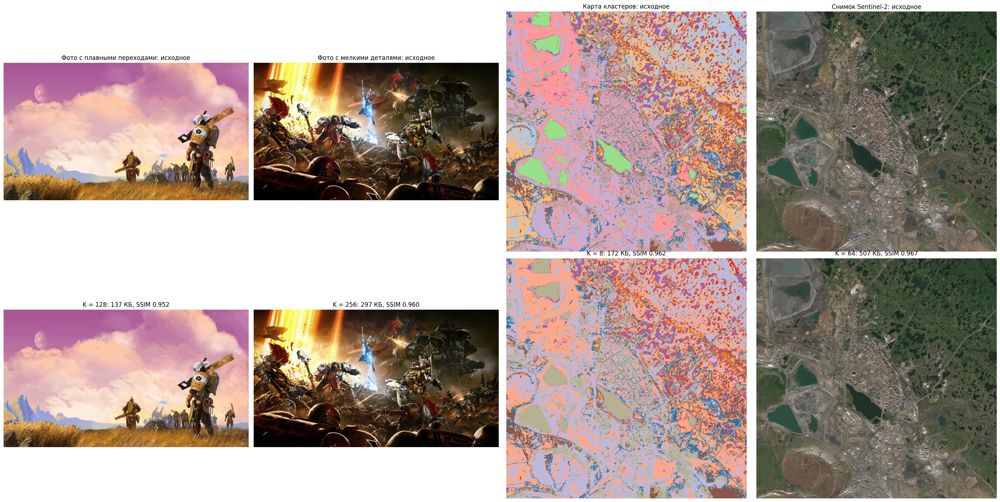

In [42]:
#@title Готовый код: исходные изображения и выбранное число цветов
fig, axes = plt.subplots(2, len(images), figsize=(7 * len(images), 14))
for j, (name, img) in enumerate(images.items()):
    k = int(choice.loc[name, 'K'])
    palette, indices = quantized[(name, k)]
    axes[0, j].imshow(img)
    axes[0, j].set_title(f'{name}: исходное')
    axes[1, j].imshow(palette[indices])
    axes[1, j].set_title(f'K = {k}: {choice.loc[name, "Палитровый PNG, КБ"]:.0f} КБ, SSIM {choice.loc[name, "SSIM"]:.3f}')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вопрос:** Для каких изображений палитровый PNG при малозаметных искажениях меньше JPEG 90, а для каких — больше? Чем отличаются эти изображения? Какой способ хранения вы выберете для фотографий, для тематических карт и для снимков в естественных цветах?

**Ответ:** Наименьшее K с SSIM ≥ 0,95:

| Изображение | K | Палитровый PNG | JPEG 90 | Отношение |
|---|---|---|---|---|
| Фото с плавными переходами | 128 | 137,2 КБ, PSNR 36,6 дБ, SSIM 0,952 | 107,0 КБ, PSNR 41,1 дБ, SSIM 0,982 | **×1,28** |
| Фото с мелкими деталями | 256 | 297,0 КБ, SSIM 0,960 | 189,6 КБ, SSIM 0,946 | **×1,57** |
| Снимок Sentinel-2 | 64 | 506,6 КБ, SSIM 0,967 | 297,8 КБ, SSIM 0,959 | **×1,70** |
| Карта кластеров | 8 | 172,0 КБ, SSIM 0,962 | 574,5 КБ, PSNR 20,0 дБ, SSIM 0,756 | **×0,30** |

**Где палитровый PNG выигрывает.** Меньше JPEG 90 он только для **карты кластеров** — в 3,3 раза, и при этом намного лучше по качеству. Для обеих фотографий и снимка Sentinel-2 он **больше** JPEG в 1,3–1,7 раза: при малозаметных искажениях им нужно 64–256 цветов, и номер цвета занимает уже 8 бит. Есть и оговорка: для тематической карты K = 8 по SSIM формально достаточно, но это сливает 12 классов в 8, а такая потеря смысла недопустима. Правильно взять K ≥ числа классов: при K = 16 карта сохраняется **точно** (PSNR = ∞) в 176,4 КБ — в 2,0 раза меньше PNG без потерь и в 3,3 раза меньше JPEG.

**Чем отличаются изображения.** У карты мало цветов, большие однородные области и резкие границы — ровно то, на чём JPEG плох (ореолы, PSNR 20 дБ), а палитра хороша. У фотографий и снимка в естественных цветах — сотни тысяч оттенков (170–225 тыс. в фото, 120 тыс. в снимке) и плавные переходы, на которые и рассчитан JPEG.

**Выбор способа хранения:**
- **фотографии** — JPEG (качество 85–90): меньше и лучше палитрового PNG при любом приемлемом качестве;
- **тематические карты** (классы, кластеры) — палитровый PNG без потерь, либо GeoTIFF uint8 с таблицей цветов, если нужна геопривязка;
- **снимки в естественных цветах** — JPEG для просмотра и иллюстраций, а для расчётов — исходный многоканальный GeoTIFF: квантизация искажает отражение.

### **6.8. Выводы по разделу 6**

Опишите, при каких условиях кластеризация цветов уменьшает размер файла, как правильно сохранять результат, как связаны число цветов, размер и качество, и чем K-средних отличается от встроенной квантизации.

**Вывод:**
1. **Когда кластеризация цветов уменьшает файл.** Только если результат сохранён как **палитра + номера цветов** (палитровый PNG): при 16 цветах в 2,0–10,8 раза меньше PNG без потерь.
2. **Как сохранять правильно.** Квантизованное изображение, сохранённое как RGB-PNG, тяжелее палитрового в 2,0–2,6 раза, а как JPEG 90 — оказывается не меньше JPEG исходного (×1,00–1,13) при двойных потерях качества.
3. **Число цветов, размер и качество.** Размер и качество растут с K одновременно: каждое удвоение K добавляет 2–3 дБ PSNR (при малых K — до 4–5 дБ) и увеличивает палитровый PNG в 1,25–1,5 раза (при K ≥ 8), время K-средних растёт почти линейно. Для малозаметных искажений (SSIM ≥ 0,95) фото с плавными переходами нужно 128 цветов, фото с мелкими деталями — 256, снимку Sentinel-2 — 64. При таких K палитровый PNG уже в 1,3–1,7 раза **больше** JPEG 90.
4. **Для каких изображений кластеризация выгодна.** Для изображений с небольшим числом цветов и резкими границами: тематическая карта при K = 16 хранится точно в 176 КБ — в 2 раза меньше PNG без потерь и в 3,3 раза меньше JPEG 90, у которого PSNR всего 20 дБ. Для фотографий и снимков в естественных цветах выгоднее JPEG.
5. **K-средних против медианного сечения PIL.** При одинаковом числе цветов K-средних даёт PSNR на 1,9–3,9 дБ выше встроенного медианного сечения PIL на фотографиях и на 0,6–3,7 дБ — на снимке, при близком (обычно на 1–10 % меньшем) размере файла. K-средних итеративно минимизирует ошибку восстановления цветов, медианное сечение лишь делит цветовой куб по числу пикселей. Зато медианное сечение работает за постоянные 0,05–0,24 с, а время K-средних растёт с K: при K = 64 он в 2–3 раза медленнее. Для максимального качества при малом числе цветов лучше K-средних, для быстрой квантизации с большим K — встроенный метод.

---

## **7. Итоговые выводы**

В выводах обязательно отразить:
1. **Территория и найденные объекты**: что нашла кластеризация, их площадь, вид в естественных цветах и в инфракрасных каналах;
2. **Классификация по Dynamic World**: точность при случайной и пространственной проверке, лучший классификатор, проблемные классы, совпадение карты с Dynamic World;
3. **Классификация и кластеризация**: что может и чего не может каждый подход на вашей территории;
4. **Сжатие изображений**: для каких изображений и при каком числе цветов кластеризация выгодна, во сколько раз уменьшается размер;
5. **Возможное практическое применение** полученных результатов.

**Выводы:**

**1. Территория и найденные объекты.** Территория — квадрат 14×14 км (19 645 га с данными) вокруг Норильска. Летний композит Sentinel-2 2024 года построен по 27 снимкам 19 дат, карта Dynamic World — мода по 48 картам. Кластеризация K-средних в GEE (K = 12) выделила:
- **хвосты и шлак** — кластер 7, 2 074 га (10,6 %): тёмные (0,06–0,08) с плоским профилем; в DW — голая земля 65 %, вода 16 %, застройка 14 %; в окне хвостохранилища — 49 % пикселей;
- **техногенные грунты** промзоны и отвалов (кластер 9, 3 724 га) и **светлые минеральные поверхности** (кластер 11, 1 698 га);
- **сухую горную тундру** (кластер 10, 1 276 га), которую DW частично называет «культурами»;
- **«иголку»** — кластер 4, 36,8 га (0,19 %) с необычностью 17,4. В него вошли 13,7 га белого технологического материала в канале у хвостохранилища, 4,6 га летних снежников и светлые крыши. В естественных цветах материал выглядит как снег, но B11 = 0,35 против 0,06 у снега, и только коротковолновый ИК показывает, что это не снег.
Поиск по расстоянию до центроидов добавил 19,6 га необычных пикселей: края снежников, узкие полосы снега вдоль бровок отвалов, цветные крыши. Артефактов композита нет.

**2. Классификация по Dynamic World.**
- Случайный лес: случайная проверка — точность 0,567 / каппа 0,513, пространственная — 0,548 / 0,491. Завышение всего 2 п. п. при разреженной выборке.
- Лучший классификатор — Gradient Boost (0,556 / 0,500), затем Random Forest, SVM, CART, Min Distance.
- Проблемные классы — кустарники (точность производителя 0,40), затопл. растительность (0,43) и деревья (0,50): в лесотундре они спектрально почти одинаковы.
- Карта совпадает с DW в 58,1 % пикселей. Равные по классам выборки раздувают редкие классы: снег 530 га против 76,5, культуры 873 против 164,5.

**3. Классификация и кластеризация.**
- **Классификация** даёт карту в привычной легенде и количественную оценку точности, но только в рамках девяти классов DW и вместе с ошибками разметки. Хвосты, шлак и отвалы она раскладывает между «голой землёй», «водой», «застройкой» и «снегом», а «культуры» в тундре ещё и расширяет.
- **Кластеризация** не знает легенды и поэтому сама разделила «голую землю» DW на три разных техногенных материала, «деревья» — на сомкнутые и редкостойные, нашла 37 га спектрально уникальных объектов и показала, где спектр опровергает визуальную гипотезу. Но названия кластерам даёт исследователь, а смысловые объекты (отвал, карьер) кластеризация не отличает от других поверхностей с тем же спектром.

**4. Сжатие изображений.** Кластеризация цветов выгодна только при сохранении в палитровый PNG: при 16 цветах файл в 2,0–10,8 раза меньше PNG без потерь, тогда как RGB-PNG квантизованного изображения в 2,0–2,6 раза тяжелее палитрового. По сравнению с JPEG 90 палитра выигрывает только у тематической карты: при K = 16 карта хранится без искажений в 176 КБ — в 3,3 раза меньше JPEG. Для фотографий и снимка в естественных цветах при SSIM ≥ 0,95 (64–256 цветов) палитровый PNG в 1,3–1,7 раза больше JPEG 90.

**5. Практическое применение.**
- **Экологический мониторинг Норильского промышленного района:** ежегодное картирование площадей хвостов, шлака, отвалов и техногенной пустоши (кластеры 7, 9, 11) и отслеживание её границы с живой лесотундрой по ИК-каналам.
- **Поиск и контроль технологических объектов:** открытые карты намыва, отстойники с окрашенной водой, новые отвалы — по центроиду «иголки» или по расстоянию до центроидов на соседних промышленных территориях (Талнах, Кайеркан).
- **Подготовка разметки:** кластеры подсказывают новые классы («хвосты и шлак», «светлый технологический материал», «сухая тундра») и места для обучающих точек. Это нужно, чтобы классификатор перестал повторять ошибки Dynamic World (культуры в тундре, «снег» на хвостах).
- **Хранение и публикация тематических карт** в палитровом PNG без потерь, а фотографий и снимков-иллюстраций — в JPEG.

---

## **Что сдавать**

1. Выполненный блокнот со всеми выводами ячеек и заполненными ответами (таблицы 2 и 3, ответы на вопросы, выводы по разделам 4–6 и итоговые выводы).
2. Папку `compressed` с файлами раздела 6 (в архиве).

## **Дополнительные задания (выполняются по желанию)**

1. **Перенос модели.** Примените классификатор, обученный на своей территории, к композиту другой территории из таблицы 1 и рассчитайте совпадение с Dynamic World. Сравните с точностью пространственной проверки и объясните разницу.
2. **Поиск по эталону.** Возьмите центроиды «иголок» своей территории и найдите на другой территории пиксели, ближе всего к ним расположенные в пространстве стандартизированных признаков. Нашлись ли объекты того же типа?
3. **Собственная реализация K-средних.** Напишите K-средних для цветов на NumPy (инициализация, назначение пикселей, пересчёт центроидов, остановка по сдвигу центроидов) и сравните с `KMeans` по времени, числу итераций и PSNR при $K = 16$.
4. **Другое цветовое пространство.** Выполните квантизацию фотографий в пространстве CIELAB (`skimage.color.rgb2lab`), где евклидово расстояние ближе к различию цветов, воспринимаемому глазом, и сравните SSIM с квантизацией в RGB при одинаковом $K$.